# Prova prática de Visão Computacional com YOLO

**Comparação YOLOv8n × YOLO11n: detecção e segmentação de equipamentos elétricos**

**Aluno:** Lucas Ferreira Neto

**Matrícula:** 223026

**Instituição:** Centro Universitário Facens (UniFacens)

Execução local em Windows / RTX 4050. Quatro modelos, **20 épocas por modelo**. Dataset: Zenodo 7884270.

## 1. Objetivos
Comparar qualidade de localização, máscaras e custo computacional em condições equivalentes, usando resultados reais e preservando dados originais e checkpoints.

## 2. Introdução teórica
YOLO é uma família de modelos de detecção de estágio único. A detecção estima classe e caixa; a segmentação de instâncias acrescenta uma máscara por objeto. Precision mede a fração de predições positivas corretas e recall a fração dos objetos recuperados. AP integra a curva precision–recall; mAP@0.5 usa IoU 0,5 e mAP@0.5:0.95 agrega dez limiares de 0,50 a 0,95. Caixas e máscaras têm IoU e métricas próprias. O ponto de precision/recall reportado pelo Ultralytics é escolhido na curva F1; o limiar visual 0,25 é usado apenas nas ilustrações.

## 3. Bibliotecas e ambiente computacional
O ambiente existente foi preservado. As dependências completas estão fixadas em requirements.txt; CUDA não foi reinstalado.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from common import load_json
display(pd.DataFrame([load_json(ROOT / 'relatorios/ambiente.json')]).T)

,0
python,"3.12.10 (tags/v3.12.10:0cc8128, Apr 8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]"
executable,C:\Users\lucas.neto\Documents\YOLO_Subestacoes\.venv\Scripts\python.exe
platform,Windows-11-10.0.26200-SP0
torch,2.12.0+cu126
ultralytics,8.4.192
cuda,12.6
cuda_available,True
disk_free_bytes,195208429568
ram_total_bytes,16866033664
ram_available_bytes,1195589632


## 4. Descrição do dataset
Gomes et al. publicaram imagens de uma subestação brasileira com 15 classes de equipamentos. O ZIP e seu MD5 oficial foram verificados. As pastas de máscaras semânticas não são usadas para inventar instâncias. A tabela abaixo descreve o conteúdo efetivamente inspecionado.

In [2]:
prep = load_json(ROOT / 'relatorios/preparacao.json')
display(pd.DataFrame([(k, str(v)) for k,v in prep.items()], columns=['Propriedade','Valor']))

,Propriedade,Valor
0,classes,"['Open blade disconnect switch', 'Closed blade disconnect switch', 'Open tandem disconnect switch', 'Closed tandem disconnect switch', 'Breaker', 'Fuse disconnect switch', 'Glass disc insulator', 'Porcelain pin insulator', 'Muffle', 'Lightning arrester', 'Recloser', 'Power transformer', 'Current transformer', 'Potential transformer', 'Tripolar disconnect switch']"
1,images_original,1660
2,json_original,1660
3,valid_images,1660
4,objects,50596
5,splits,"{'train': 1162, 'test': 249, 'val': 249}"
6,annotation_types,{'polygon': 52886}
7,grouped_instances,0
8,exact_duplicate_images,1
9,issues,3665


In [3]:
audit = load_json(ROOT/'relatorios/auditoria_fonte.json')
print(audit['note'])
print('Polígonos de equipamentos nos JSONs:',audit['raw_equipment_polygons'],'| instâncias após deduplicação:',audit['converted_instances'])
display(pd.read_csv(ROOT/'relatorios/auditoria_contagens.csv'))

As contagens do arquivo original diferem da descrição do Zenodo. Foram usados os JSONs reais, sem criar objetos para forçar correspondência com os metadados.
Polígonos de equipamentos nos JSONs: 50602 | instâncias após deduplicação: 50596


,classe,publicado_zenodo,poligonos_json,instancias_convertidas,diferenca_json_publicado
0,Open blade disconnect switch,310,308,308,-2
1,Closed blade disconnect switch,5243,5224,5221,-19
2,Open tandem disconnect switch,1599,1596,1596,-3
3,Closed tandem disconnect switch,966,957,957,-9
4,Breaker,980,980,979,0
5,Fuse disconnect switch,355,355,355,0
6,Glass disc insulator,3185,3180,3180,-5
7,Porcelain pin insulator,26499,26450,26448,-49
8,Muffle,1354,1354,1354,0
9,Lightning arrester,1976,1974,1974,-2


In [4]:
masks = load_json(ROOT / 'relatorios/inspecao_mascaras.json')
for name,info in masks.items():
    print(name, 'arquivos:',info['files'],'ausentes:',len(info['missing_for_images']),'órfãos:',len(info['orphan_masks']))
    display(pd.DataFrame(info['samples']))

14_masks arquivos: 1660 ausentes: 0 órfãos: 0


,file,mode,size,colors
0,1PANO0001.png,RGB,"[4000, 3000]","[[337800, [255, 182, 0]], [37748, [121, 121, 121]], [86974, [40, 0, 186]], [40640, [97, 16, 162]], [19200, [154, 32, 121]], [17525, [143, 211, 255]], [15779, [138, 138, 0]], [11444334, [0, 0, 0]]]"
1,202107131404432209708.png,RGB,"[704, 480]","[[19690, [121, 121, 121]], [173, [162, 243, 162]], [318057, [0, 0, 0]]]"
2,202107131406516153763.png,RGB,"[704, 480]","[[4371, [255, 97, 178]], [19400, [121, 121, 121]], [314149, [0, 0, 0]]]"


15_masks arquivos: 1660 ausentes: 0 órfãos: 0


,file,mode,size,colors
0,1PANO0001.png,RGB,"[4000, 3000]","[[68073, [255, 255, 125]], [37748, [121, 121, 121]], [86974, [40, 0, 186]], [40640, [97, 16, 162]], [337800, [255, 182, 0]], [19200, [154, 32, 121]], [17525, [143, 211, 255]], [15779, [138, 138, 0]], [11376261, [0, 0, 0]]]"
1,202107131404432209708.png,RGB,"[704, 480]","[[19690, [121, 121, 121]], [173, [162, 243, 162]], [318057, [0, 0, 0]]]"
2,202107131406516153763.png,RGB,"[704, 480]","[[780, [255, 255, 125]], [19400, [121, 121, 121]], [4371, [255, 97, 178]], [313369, [0, 0, 0]]]"


porcelain_masks arquivos: 1660 ausentes: 0 órfãos: 0


,file,mode,size,colors
0,1PANO0001.png,RGB,"[4000, 3000]","[[97470, [255, 255, 125]], [11902530, [0, 0, 0]]]"
1,202107131404432209708.png,RGB,"[704, 480]","[[337920, [0, 0, 0]]]"
2,202107131406516153763.png,RGB,"[704, 480]","[[2176, [255, 255, 125]], [335744, [0, 0, 0]]]"


## 5. Exploração e distribuição das classes
Contagens após validação geométrica e agrupamento explícito de instâncias. O arquivo correcoes_descartes.json registra todas as alterações e exclusões.

split,test,train,val
classe,,,
Breaker,143,657,179
Closed blade disconnect switch,718,3761,742
Closed tandem disconnect switch,137,647,173
Current transformer,365,1439,324
Fuse disconnect switch,45,249,61
Glass disc insulator,493,2220,467
Lightning arrester,316,1312,346
Muffle,261,894,199
Open blade disconnect switch,40,214,54


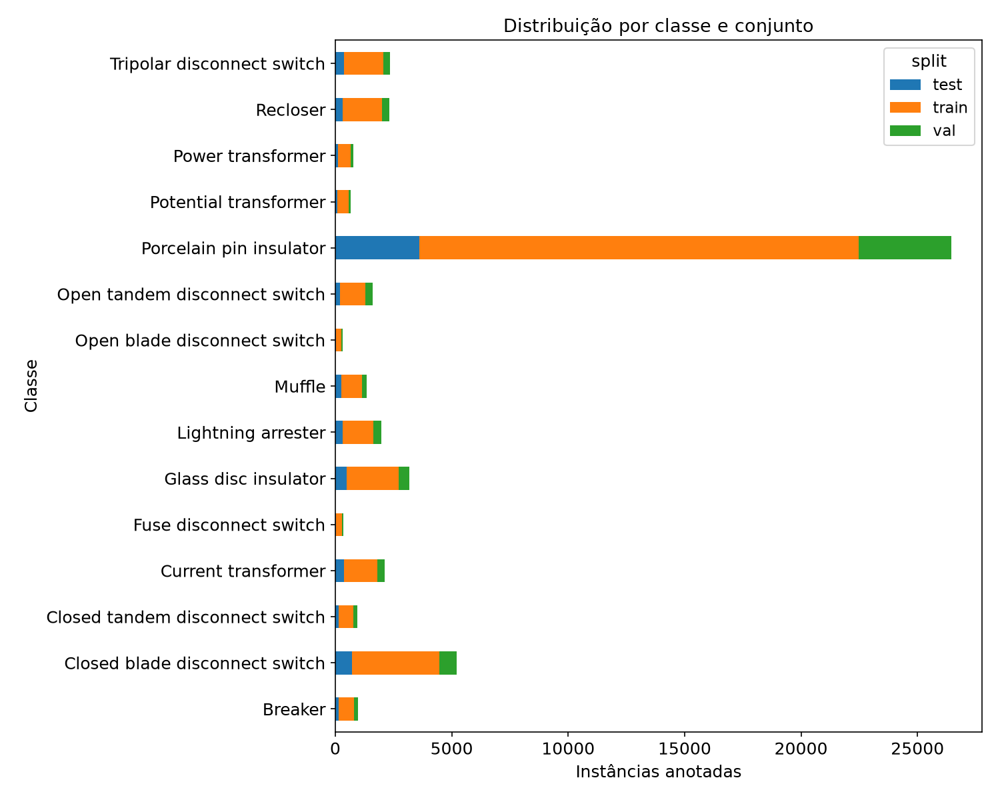

In [5]:
dist = pd.read_csv(ROOT / 'relatorios/distribuicao_classes.csv')
display(dist.pivot(index='classe', columns='split', values='objetos'))
display(Image(filename=str(ROOT / 'graficos/distribuicao.png')))

## 6. Conversão das anotações
Os JSONs reais são LabelMe: shapes contêm label, points, shape_type e group_id. O fundo não recebe ID YOLO. Para cada instância, a caixa é o mínimo retângulo envolvente; centro e dimensões são divididos por largura e altura. Os vértices dos polígonos são normalizados da mesma forma. Geometrias inválidas são reparadas, recortadas geometricamente na imagem e registradas. Partes da mesma instância são representadas com pontes de largura zero, pois o TXT YOLO não codifica MultiPolygon/furos. Veja o código integral no apêndice.

In [6]:
issues = load_json(ROOT / 'relatorios/correcoes_descartes.json')
display(pd.DataFrame(issues).head(20))
print('Total de registros de correção/descarte/limitação:', len(issues))

,image,shape,action,reason,group
0,1PANO0001,24.0,corrigida,make_valid: polígono inválido,NaN
1,1PANO0001,NaN,limitação,formato YOLO não representa furos; usa contorno externo,"('Glass disc insulator', 'shape', 24)"
2,1PANO0001,99.0,corrigida,make_valid: polígono inválido,NaN
3,1PANO0001,NaN,corrigida,partes da mesma instância unidas com pontes de largura zero,"('Porcelain pin insulator', 'shape', 99)"
4,1PANO0001,NaN,fundo ignorado,Background não é uma classe de equipamento YOLO,"('Background', 'shape', 116)"
5,1PANO0001,NaN,fundo ignorado,Background não é uma classe de equipamento YOLO,"('Background', 'shape', 117)"
6,1PANO0001,NaN,fundo ignorado,Background não é uma classe de equipamento YOLO,"('Background', 'shape', 118)"
7,1PANO0001,NaN,fundo ignorado,Background não é uma classe de equipamento YOLO,"('Background', 'shape', 119)"
8,202107131406516153763,NaN,fundo ignorado,Background não é uma classe de equipamento YOLO,"('Background', 'shape', 11)"
9,202107131406516153763,NaN,fundo ignorado,Background não é uma classe de equipamento YOLO,"('Background', 'shape', 13)"


Total de registros de correção/descarte/limitação: 3665


As dimensões consideradas são as orientadas pelo EXIF, iguais às usadas pelo decodificador OpenCV/Ultralytics e pelos JSONs. Os JPEGs não são recodificados. Duplicatas literais de classe e vértices são removidas nas duas tarefas, com registro. A primeira verificação foi arquivada em relatorios/preparacao_revisao_EXIF antes de qualquer treinamento; a versão final preserva todas as imagens dimensionalmente válidas.

## 7. Validação visual de três imagens
Cada figura apresenta original, caixas e polígonos anotados. Cores identificam classes; sobreposição transparente permite verificar contornos e oclusões. As figuras foram geradas das mesmas coordenadas gravadas nos TXT YOLO.

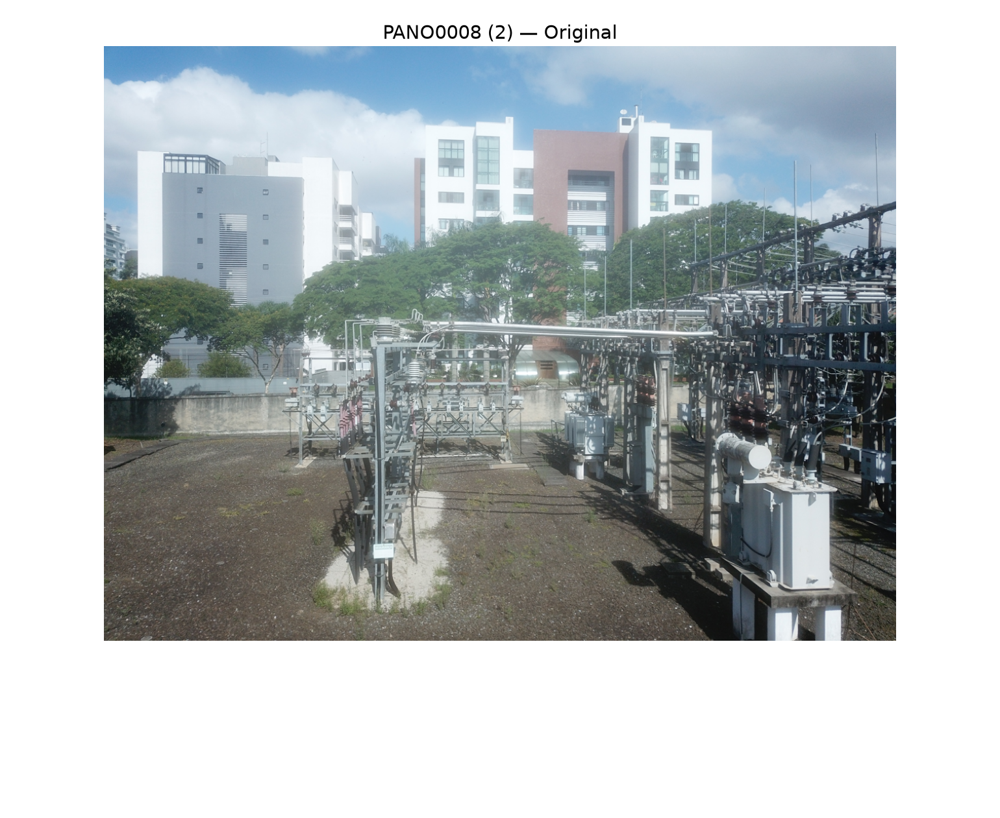

In [7]:
display(Image(filename=str(ROOT / 'graficos/validacao_1_original.png')))

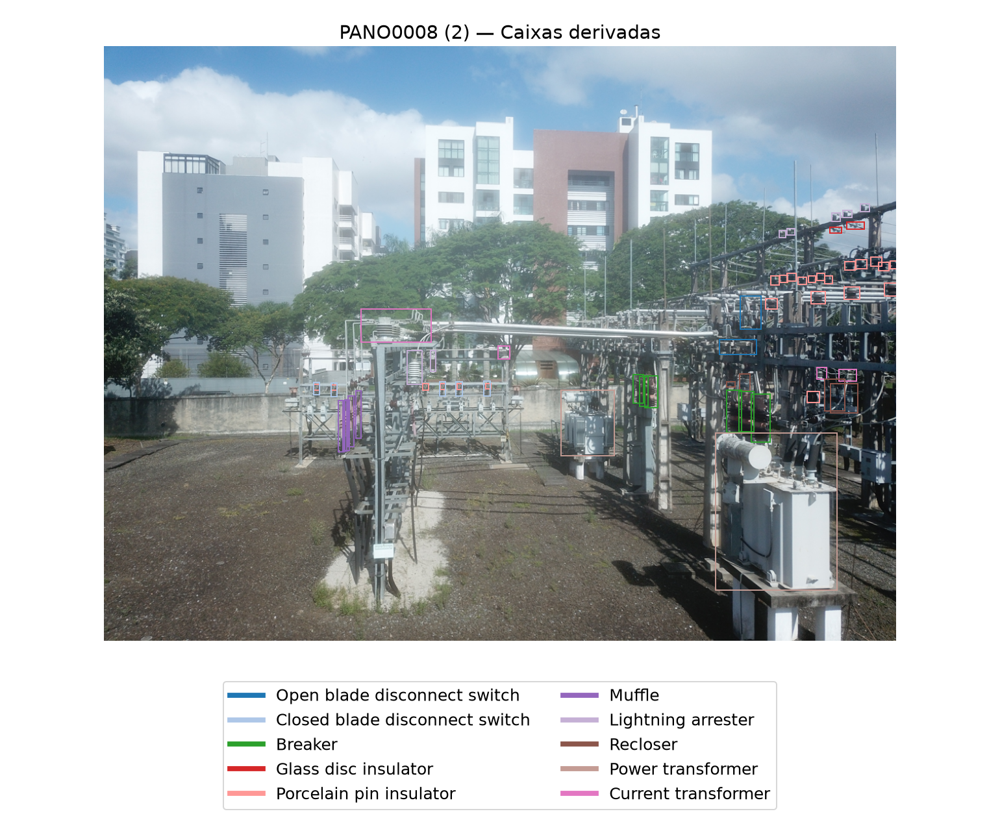

In [8]:
display(Image(filename=str(ROOT / 'graficos/validacao_1_boxes.png')))

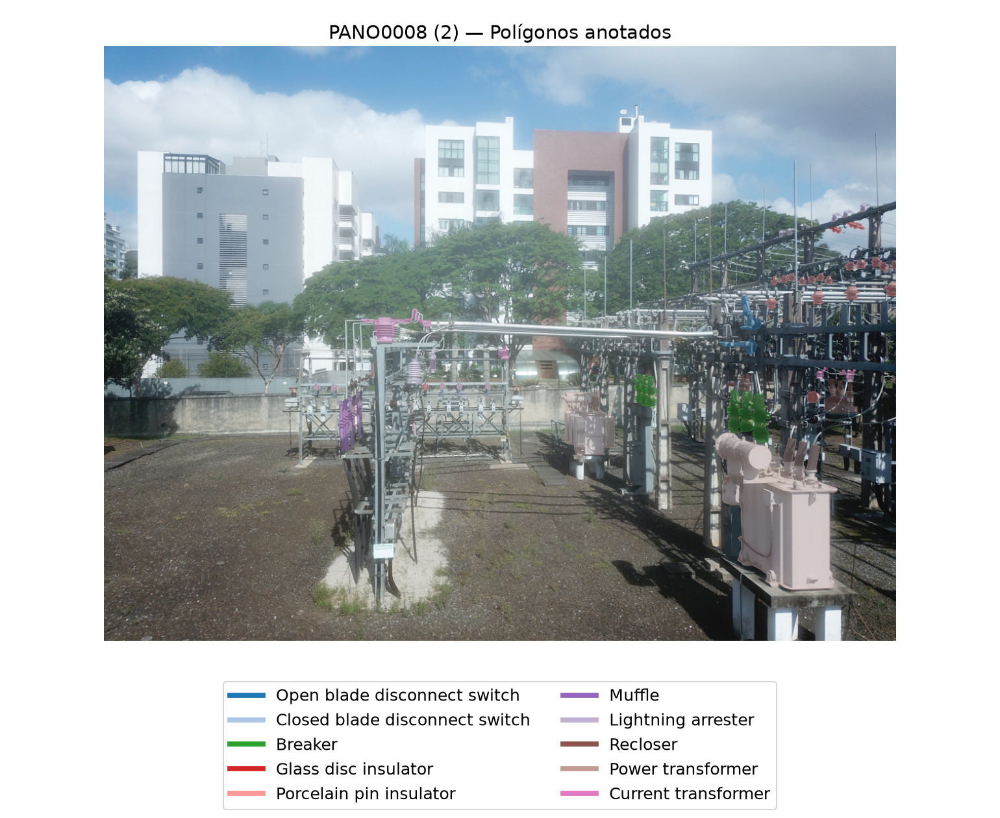

In [9]:
display(Image(filename=str(ROOT / 'graficos/validacao_1_polygons.png')))

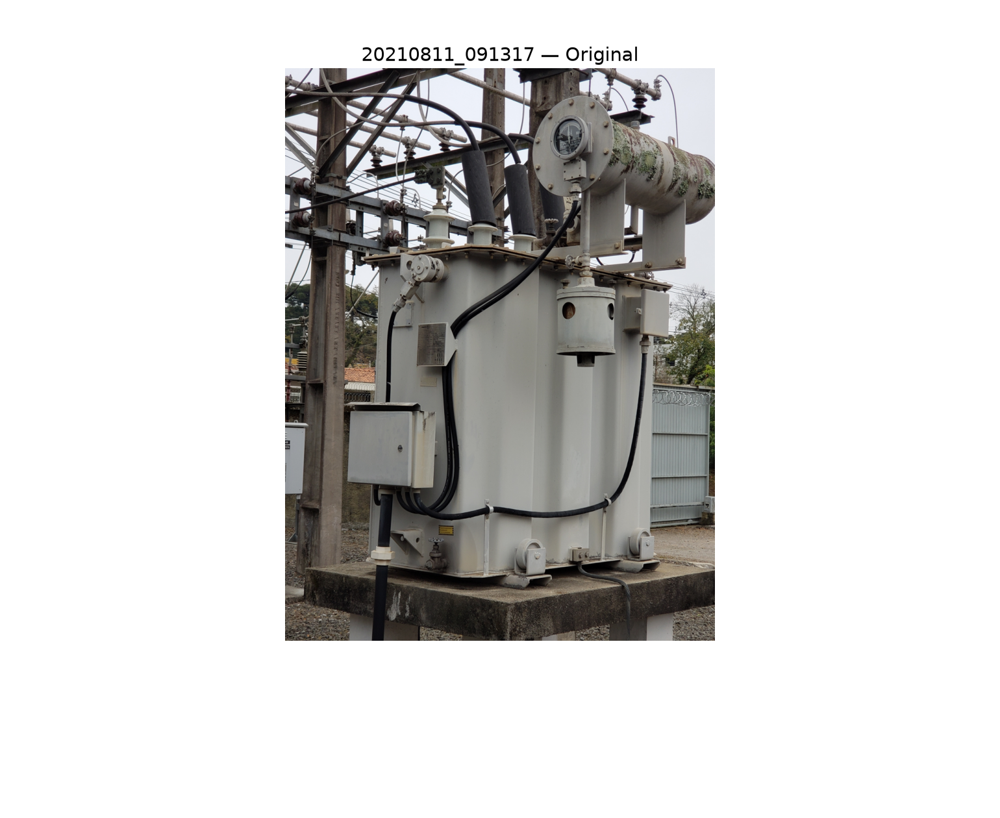

In [10]:
display(Image(filename=str(ROOT / 'graficos/validacao_2_original.png')))

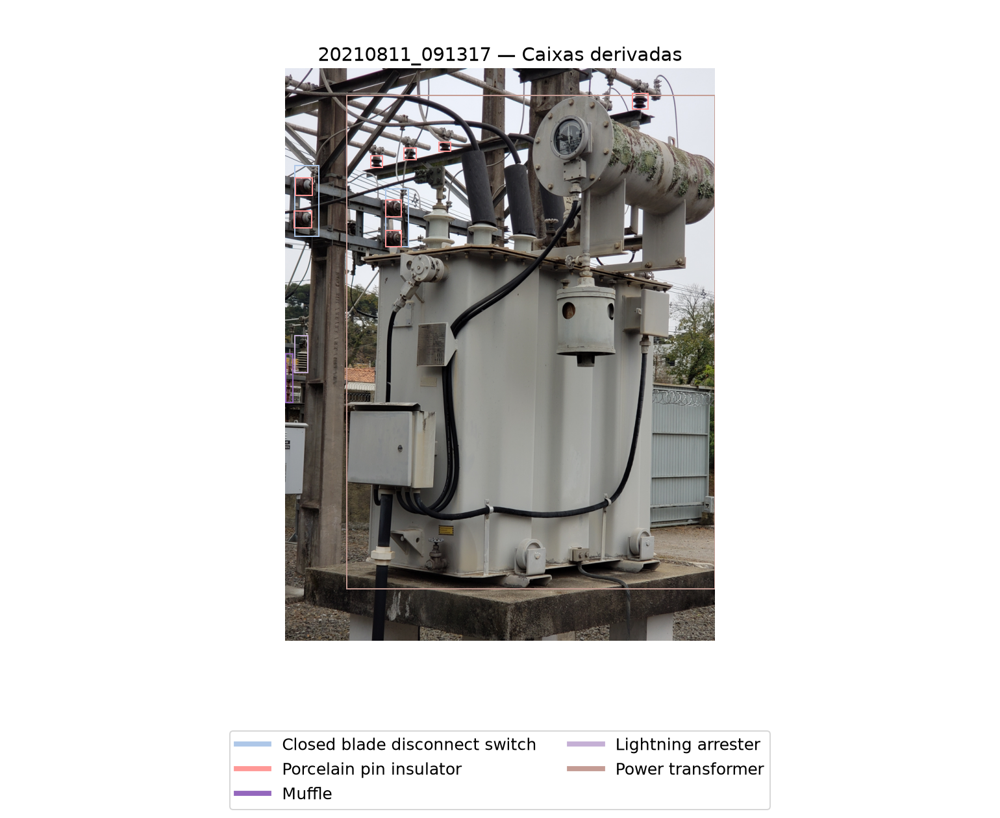

In [11]:
display(Image(filename=str(ROOT / 'graficos/validacao_2_boxes.png')))

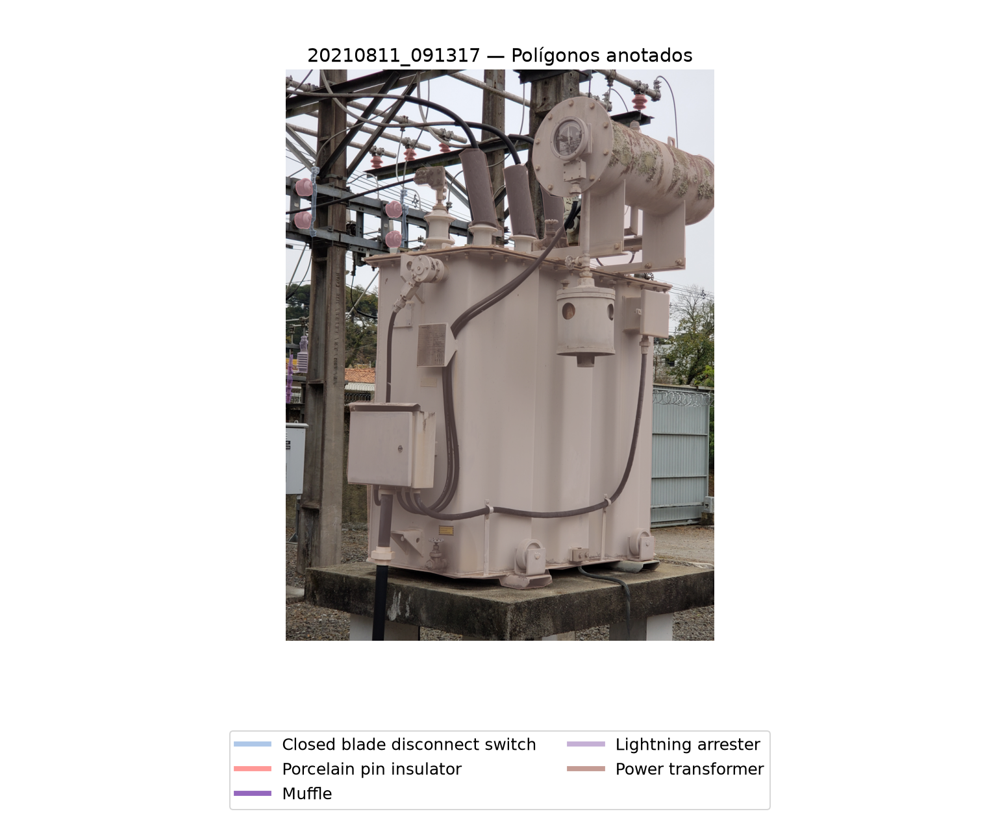

In [12]:
display(Image(filename=str(ROOT / 'graficos/validacao_2_polygons.png')))

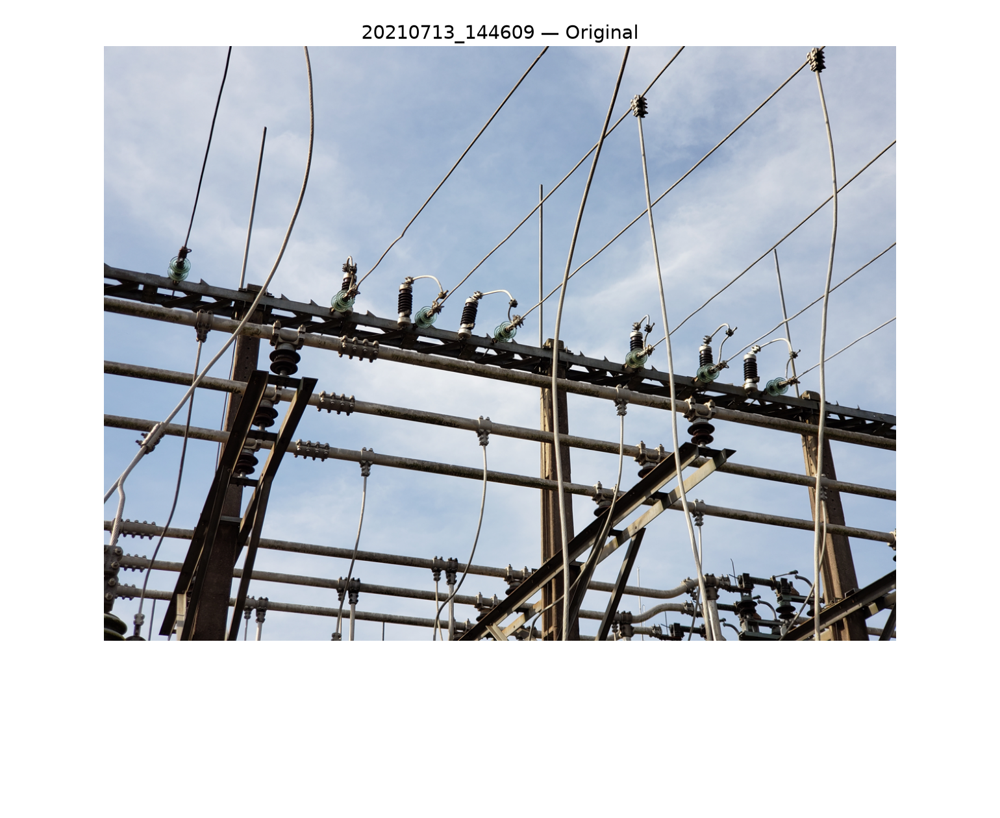

In [13]:
display(Image(filename=str(ROOT / 'graficos/validacao_3_original.png')))

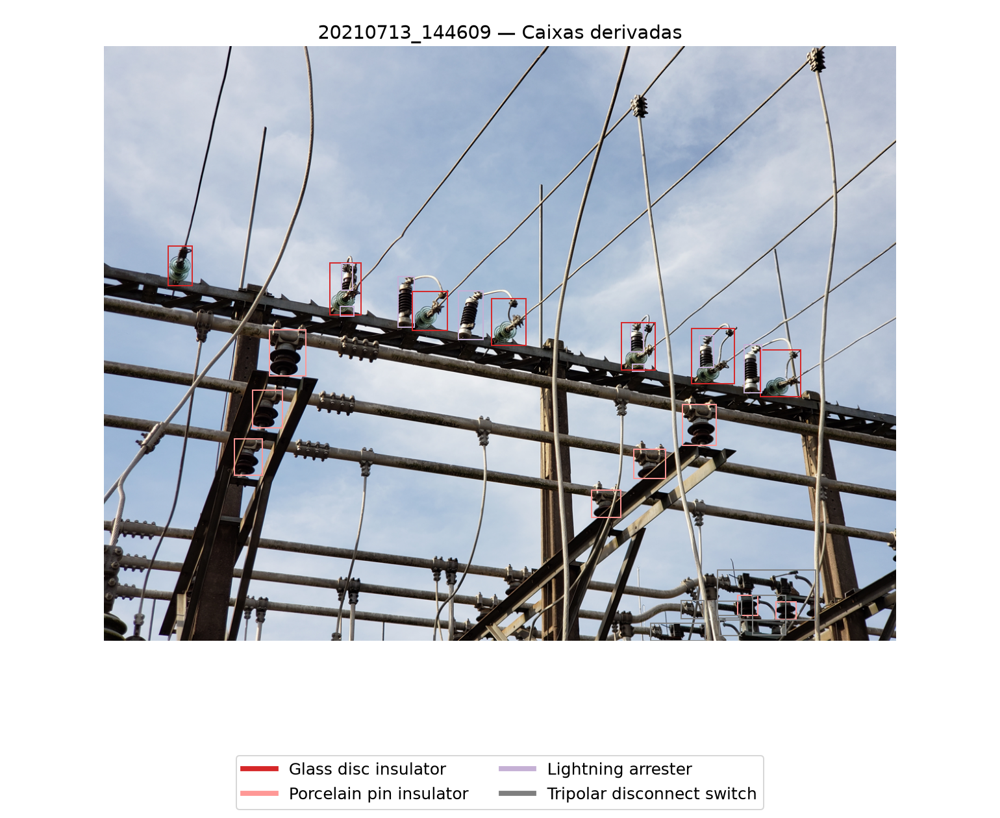

In [14]:
display(Image(filename=str(ROOT / 'graficos/validacao_3_boxes.png')))

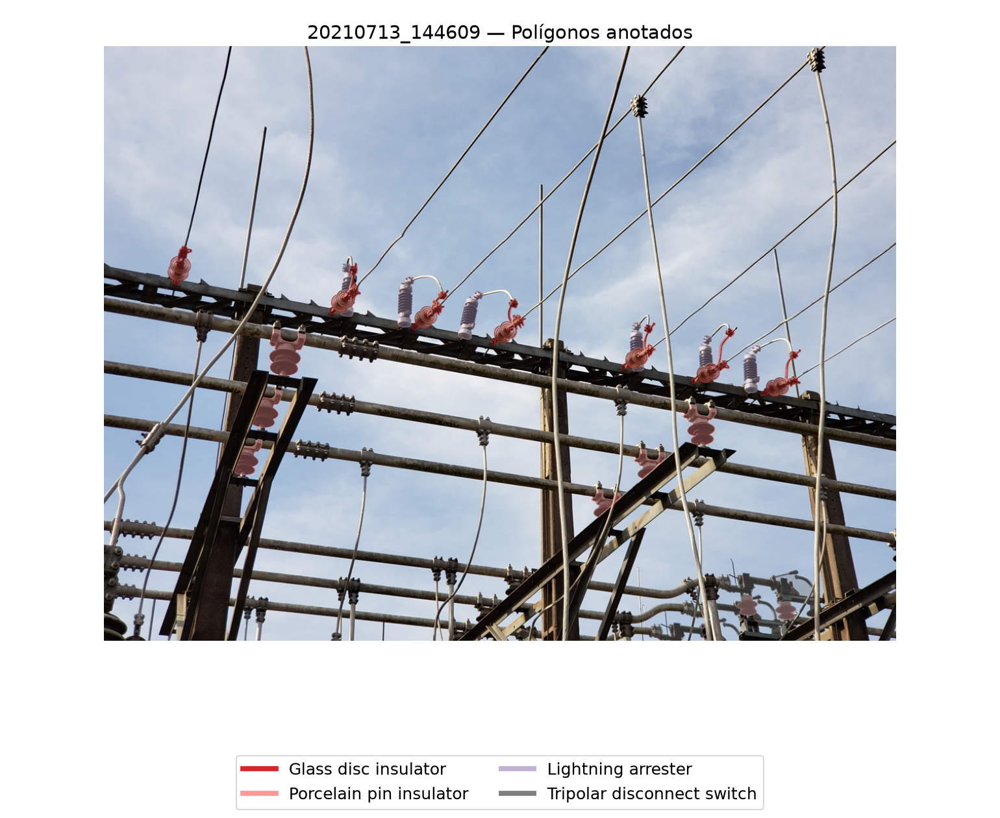

In [15]:
display(Image(filename=str(ROOT / 'graficos/validacao_3_polygons.png')))

## 8. Divisão dos dados
70% treino, 15% validação e 15% teste, seed 42, com arredondamento por imagem e agrupamento SHA256 de duplicatas exatas. Ambas as tarefas usam o mesmo manifesto anotacoes_convertidas.json. Nenhuma imagem de teste participa de treino, teste funcional ou escolha de hiperparâmetros. Correlação visual ou temporal entre imagens diferentes continua sendo uma limitação.

In [16]:
manifest = load_json(ROOT / 'relatorios/anotacoes_convertidas.json')
display(pd.Series([r['split'] for r in manifest]).value_counts().to_frame('Imagens'))
sets = {s: {r['sha256'] for r in manifest if r['split']==s} for s in ['train','val','test']}
assert all(not sets[a] & sets[b] for a,b in [('train','val'),('train','test'),('val','test')])
print('Verificação de duplicatas exatas entre conjuntos: aprovada')

,Imagens
train,1162
test,249
val,249


Verificação de duplicatas exatas entre conjuntos: aprovada


## 9. Configuração dos experimentos
Treinos sequenciais, checkpoints por época, SGD, resolução 640, seed 42, device 0, AMP quando aprovado no teste do Ultralytics, patience 0 e workers 0. Os demais parâmetros são os padrões da versão fixada e estão registrados em args.yaml. O batch efetivamente adotado e a eventual justificativa de OOM aparecem abaixo. O ensaio funcional usa uma amostra densa do treino por uma época e é armazenado separadamente.

In [17]:
from common import TRAIN, MODELS
display(pd.DataFrame([(k,str(v)) for k,v in TRAIN.items()],columns=['Parâmetro','Configuração inicial']))
for task,arch,_ in MODELS:
    print(task, arch, load_json(ROOT / 'resultados' / task / arch / 'concluido.json'))
for p in (ROOT/'relatorios').glob('ajuste_batch_*.json'):
    print(p.name, load_json(p))

,Parâmetro,Configuração inicial
0,epochs,20
1,imgsz,640
2,batch,8
3,optimizer,SGD
4,lr0,0.01
5,seed,42
6,device,0
7,amp,True
8,patience,0
9,workers,0


detection YOLOv8 {'epochs': 20, 'batch': 8, 'seconds_this_session': 1059.14211720007, 'epoch_seconds_total': 1037.355842799996, 'first_epoch_seconds': 63.65257819998078, 'functional': False, 'effective_amp': True, 'effective_batch': 8, 'optimizer_class': 'SGD', 'note': 'Tempos por época incluem validação; tempo de sessão inclui inicialização e avaliação final.'}
detection YOLO11 {'epochs': 20, 'batch': 8, 'seconds_this_session': 1004.0496194999432, 'epoch_seconds_total': 984.550812099711, 'first_epoch_seconds': 69.26333019998856, 'functional': False, 'effective_amp': True, 'effective_batch': 8, 'optimizer_class': 'SGD', 'note': 'Tempos por época incluem validação; tempo de sessão inclui inicialização e avaliação final.'}
segmentation YOLOv8 {'epochs': 20, 'batch': 8, 'seconds_this_session': 1580.4175546000479, 'epoch_seconds_total': 1553.6660152999684, 'first_epoch_seconds': 91.45916660001967, 'functional': False, 'effective_amp': True, 'effective_batch': 8, 'optimizer_class': 'SGD', '

In [18]:
import time
state = load_json(ROOT / 'relatorios/execucao.json')
print(state.get('time_scope',''))
print('Tempo corrido até esta análise (horas):', round((time.time()-state['started'])/3600, 3))
for task,arch,_ in MODELS:
    timing = load_json(ROOT/'resultados'/task/arch/'tempos_epocas.json')
    print(task,arch,'primeira época (s):',round(timing[0]['seconds'],2),'soma das épocas (s):',round(sum(t['seconds'] for t in timing),2))

Tempo corrido desde registro inicial do download; inclui download, preparação e execução.
Tempo corrido até esta análise (horas): 2.19
detection YOLOv8 primeira época (s): 63.65 soma das épocas (s): 1037.36
detection YOLO11 primeira época (s): 69.26 soma das épocas (s): 984.55
segmentation YOLOv8 primeira época (s): 91.46 soma das épocas (s): 1553.67
segmentation YOLO11 primeira época (s): 117.32 soma das épocas (s): 1735.8


## 10. Treinamento de detecção
Pesos iniciais: yolov8n.pt e yolo11n.pt. Os experimentos finais têm exatamente 20 linhas de métricas por época. best.pt é escolhido pela validação; last.pt permite retomada antes da finalização. Os treinos não são repetidos para gerar este documento.

In [19]:
for arch in ['YOLOv8','YOLO11']:
    f = pd.read_csv(ROOT / 'resultados/detection' / arch / 'results.csv')
    assert len(f)==20
    print('Detecção',arch,'—',len(f),'épocas')
    display(f.tail(3))

Detecção YOLOv8 — 20 épocas


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
17,18,953.355,1.43440,0.95646,1.01722,0.70028,0.50494,0.55532,0.31768,1.48420,0.96410,1.07133,0.001585,0.001585,0.001585
18,19,994.794,1.41167,0.93526,1.01165,0.68686,0.50410,0.55529,0.31838,1.48756,0.95518,1.06925,0.001090,0.001090,0.001090
19,20,1037.430,1.40753,0.93365,1.00770,0.72304,0.50854,0.56152,0.32304,1.46391,0.94889,1.06058,0.000595,0.000595,0.000595


Detecção YOLO11 — 20 épocas


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
17,18,891.946,1.44129,0.95712,1.01212,0.68363,0.49214,0.53988,0.30599,1.47492,0.98090,1.05275,0.001585,0.001585,0.001585
18,19,938.695,1.41622,0.93742,1.00787,0.70320,0.51106,0.55356,0.31582,1.46649,0.96773,1.04928,0.001090,0.001090,0.001090
19,20,984.582,1.41377,0.93106,1.00610,0.69793,0.51651,0.56507,0.32504,1.44990,0.95735,1.03980,0.000595,0.000595,0.000595


## 11. Treinamento de segmentação
Pesos iniciais: yolov8n-seg.pt e yolo11n-seg.pt. Máscaras e caixas têm métricas separadas. As perdas incluem os componentes box, seg, cls e dfl quando fornecidos pelo treinador. overlap_mask=False preserva máscaras-alvo independentes em regiões de sobreposição; mask_ratio=4 mantém a resolução padrão dos alvos nas duas arquiteturas.

A versão instalada também registra sem_loss. Nestes modelos, esse componente auxiliar permanece zero porque não há predição semântica auxiliar; ele não indica segmentação perfeita. A perda de instâncias relevante é seg_loss, em conjunto com as métricas de máscaras.

In [20]:
for arch in ['YOLOv8','YOLO11']:
    f = pd.read_csv(ROOT / 'resultados/segmentation' / arch / 'results.csv')
    assert len(f)==20
    print('Segmentação',arch,'—',len(f),'épocas')
    display(f.tail(3))

Segmentação YOLOv8 — 20 épocas


,epoch,time,train/box_loss,train/seg_loss,train/cls_loss,train/dfl_loss,train/sem_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),val/box_loss,val/seg_loss,val/cls_loss,val/dfl_loss,val/sem_loss,lr/pg0,lr/pg1,lr/pg2
17,18,1422.92,1.42948,2.36155,0.97633,0.99982,0,0.71481,0.50231,0.55216,0.31405,0.69486,0.47525,0.51884,0.24539,1.47470,2.37038,0.99004,1.04552,0,0.001585,0.001585,0.001585
18,19,1488.51,1.40696,2.34451,0.95706,0.99614,0,0.71364,0.50224,0.55479,0.31442,0.65979,0.48091,0.51140,0.24192,1.47361,2.36799,0.99424,1.04103,0,0.001090,0.001090,0.001090
19,20,1553.69,1.40245,2.33130,0.95548,0.99517,0,0.69769,0.52651,0.56777,0.32609,0.65376,0.50442,0.52962,0.25255,1.44384,2.34068,0.96520,1.03430,0,0.000595,0.000595,0.000595


Segmentação YOLO11 — 20 épocas


,epoch,time,train/box_loss,train/seg_loss,train/cls_loss,train/dfl_loss,train/sem_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),val/box_loss,val/seg_loss,val/cls_loss,val/dfl_loss,val/sem_loss,lr/pg0,lr/pg1,lr/pg2
17,18,1587.36,1.43534,2.34686,0.98237,0.99518,0,0.72170,0.50110,0.55111,0.31146,0.69267,0.47683,0.51048,0.24336,1.46344,2.32939,1.00515,1.03373,0,0.001585,0.001585,0.001585
18,19,1660.22,1.41883,2.32647,0.97034,0.99171,0,0.73103,0.49933,0.55042,0.31317,0.70442,0.47958,0.50734,0.24159,1.46892,2.32637,1.00007,1.04079,0,0.001090,0.001090,0.001090
19,20,1735.72,1.40738,2.30947,0.96512,0.98842,0,0.71404,0.50834,0.55747,0.31897,0.69748,0.49030,0.52213,0.25096,1.44466,2.30666,0.98471,1.03442,0,0.000595,0.000595,0.000595


## 12. Avaliação na validação e no teste
Todos os números abaixo provêm de best.pt. Validação e teste usam imgsz 640, CUDA, FP16, conf 0,001, IoU NMS 0,7 e max_det 300. O teste foi reservado para avaliação final. O tempo interno de inferência é média por imagem do validador. Um benchmark adicional usa lote 1, cinco aquecimentos e 30 repetições na mesma imagem de validação, com sincronização CUDA; a latência total inclui leitura e a API predict. A contagem de parâmetros é anterior à fusão Conv/BatchNorm.

In [21]:
metrics = pd.read_csv(ROOT / 'relatorios/metricas_comparativas.csv')
for s in ['val','test']:
    print('Conjunto:', s)
    display(metrics[metrics.split==s].round(5))

Conjunto: val


,task,model,split,metric_type,precision,recall,map50,map50_95,parameters,inference_ms,preprocess_ms,postprocess_ms,training_seconds,batch,latency_e2e_mean_ms,latency_e2e_std_ms
0,detection,YOLOv8,val,box,0.72059,0.50785,0.56122,0.32271,3141405,2.62883,0.92640,1.64308,1037.35584,8,12.17723,2.48112
2,detection,YOLO11,val,box,0.69533,0.51765,0.56458,0.32427,2608285,42.27211,0.94668,1.57049,984.55081,8,14.39714,2.80545
4,segmentation,YOLOv8,val,box,0.70182,0.52512,0.56754,0.32609,3394173,2.31397,1.72960,3.25147,1553.66602,8,15.48328,2.69602
5,segmentation,YOLOv8,val,mask,0.66075,0.50071,0.53008,0.25295,3394173,2.31397,1.72960,3.25147,1553.66602,8,15.48328,2.69602
8,segmentation,YOLO11,val,box,0.71402,0.50937,0.55861,0.31989,2861053,2.26799,1.58640,3.42491,1735.79515,8,15.73504,2.34133
9,segmentation,YOLO11,val,mask,0.69541,0.49204,0.52378,0.25166,2861053,2.26799,1.58640,3.42491,1735.79515,8,15.73504,2.34133


Conjunto: test


,task,model,split,metric_type,precision,recall,map50,map50_95,parameters,inference_ms,preprocess_ms,postprocess_ms,training_seconds,batch,latency_e2e_mean_ms,latency_e2e_std_ms
1,detection,YOLOv8,test,box,0.72311,0.50197,0.54390,0.30721,3141405,1.47378,0.90847,1.50453,1037.35584,8,31.69894,28.84508
3,detection,YOLO11,test,box,0.73519,0.48686,0.54321,0.31265,2608285,1.70642,0.85691,1.58070,984.55081,8,13.74510,3.12713
6,segmentation,YOLOv8,test,box,0.71024,0.48028,0.52590,0.30030,3394173,2.04075,1.65926,2.33529,1553.66602,8,14.07401,2.60034
7,segmentation,YOLOv8,test,mask,0.66620,0.45756,0.49083,0.23441,3394173,2.04075,1.65926,2.33529,1553.66602,8,14.07401,2.60034
10,segmentation,YOLO11,test,box,0.71536,0.49277,0.53035,0.30380,2861053,3.78169,1.30330,3.34365,1735.79515,8,16.17645,5.52230
11,segmentation,YOLO11,test,mask,0.70129,0.47044,0.50228,0.23938,2861053,3.78169,1.30330,3.34365,1735.79515,8,16.17645,5.52230


### Benchmark complementar de latência
A dispersão das janelas originais motivou um ensaio adicional, sem refazer avaliações de qualidade ou treinos. Mesma imagem real de validação, lote 1, FP16 CUDA, dez aquecimentos e três rodadas de 30 repetições. Todas as 90 observações por modelo foram preservadas, sem excluir outliers. Média, desvio, mediana e P95 estão abaixo. As recomendações de velocidade usam a mediana deste ensaio; as medidas originais continuam nas tabelas anteriores.

In [22]:
display(pd.read_csv(ROOT/'relatorios/benchmark_padronizado.csv').round(4))
print(load_json(ROOT/'relatorios/benchmark_padronizado.json')['scope'])

,task,model,mean_ms,std_ms,median_ms,p95_ms,samples
0,detection,YOLOv8,11.9496,2.6671,11.0943,17.0003,90
1,detection,YOLO11,13.7780,3.0615,13.1928,18.6612,90
2,segmentation,YOLOv8,12.4148,2.5770,11.5747,18.0820,90
3,segmentation,YOLO11,17.0702,3.9494,17.5873,23.1146,90


API predict E2E: leitura + processamento + modelo + NMS, FP16 CUDA, imagem real de validação. Todos os valores mantidos, sem exclusão de outliers. Benchmark adicional motivado por dispersão nas medições originais, que foram preservadas.


## 13. Gráficos comparativos
Os componentes das perdas aparecem em eixos separados para não somar escalas distintas. mAP de caixas e máscaras é separado. Parâmetros medem complexidade de armazenamento; não substituem latência ou FLOPs. A comparação de eficiência combina AP com a latência observada, sem atribuir uma única pontuação arbitrária.

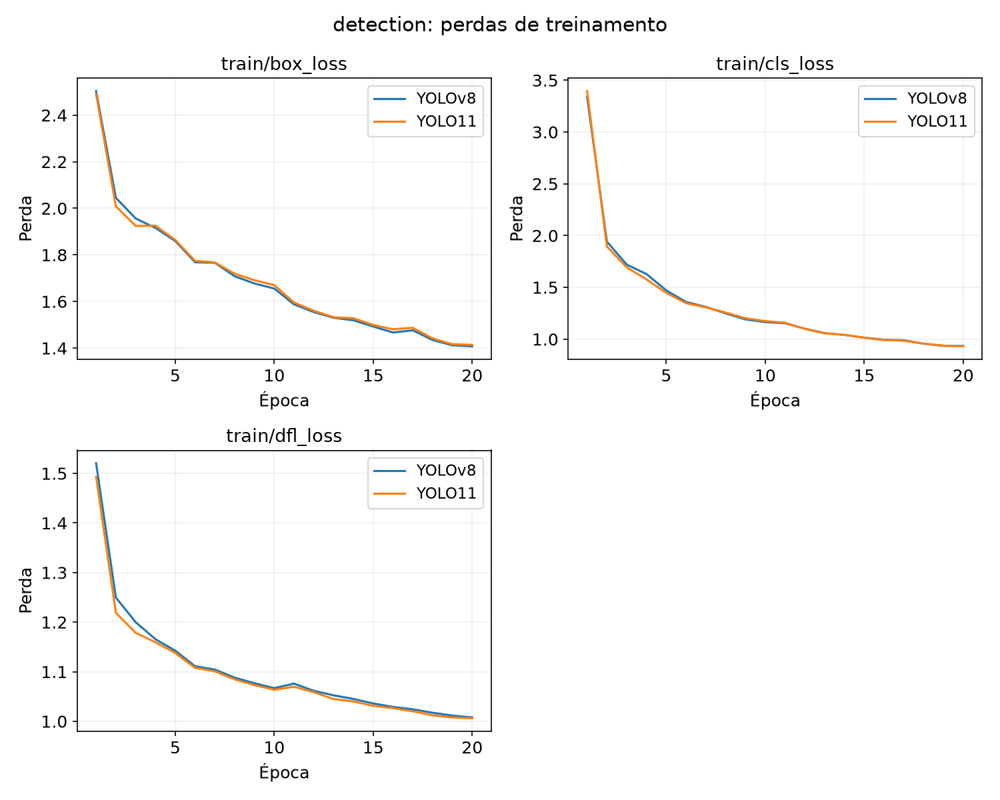

In [23]:
display(Image(filename=str(ROOT / 'graficos/detection_train_loss.png')))

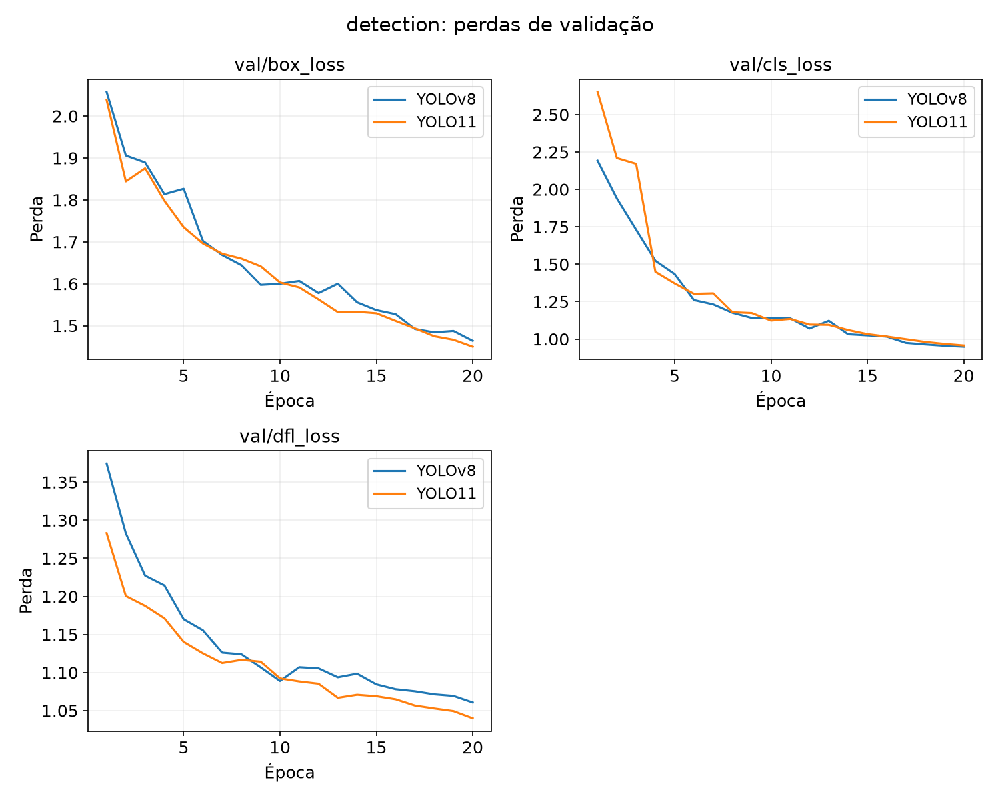

In [24]:
display(Image(filename=str(ROOT / 'graficos/detection_val_loss.png')))

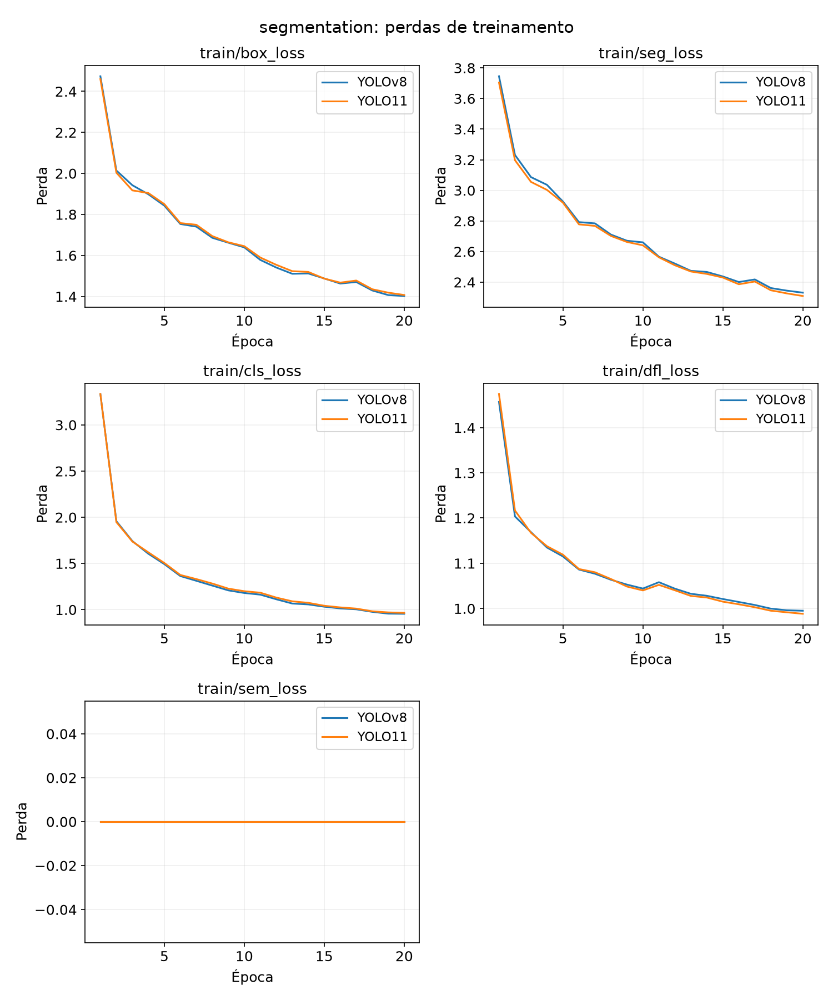

In [25]:
display(Image(filename=str(ROOT / 'graficos/segmentation_train_loss.png')))

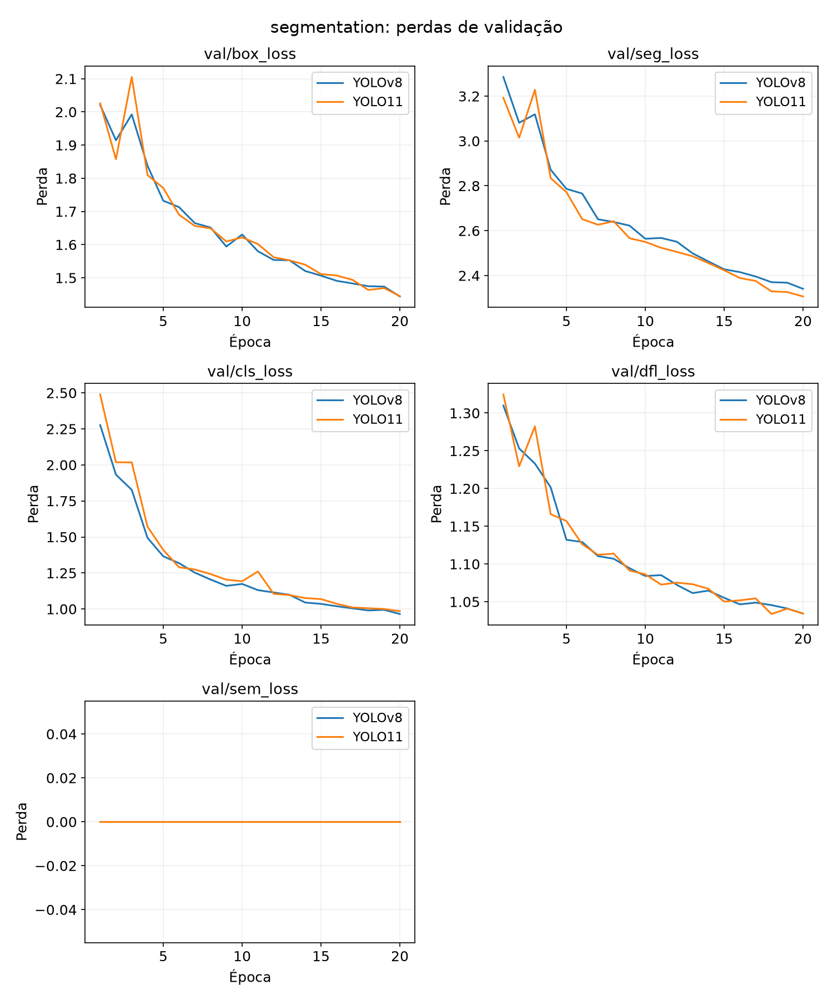

In [26]:
display(Image(filename=str(ROOT / 'graficos/segmentation_val_loss.png')))

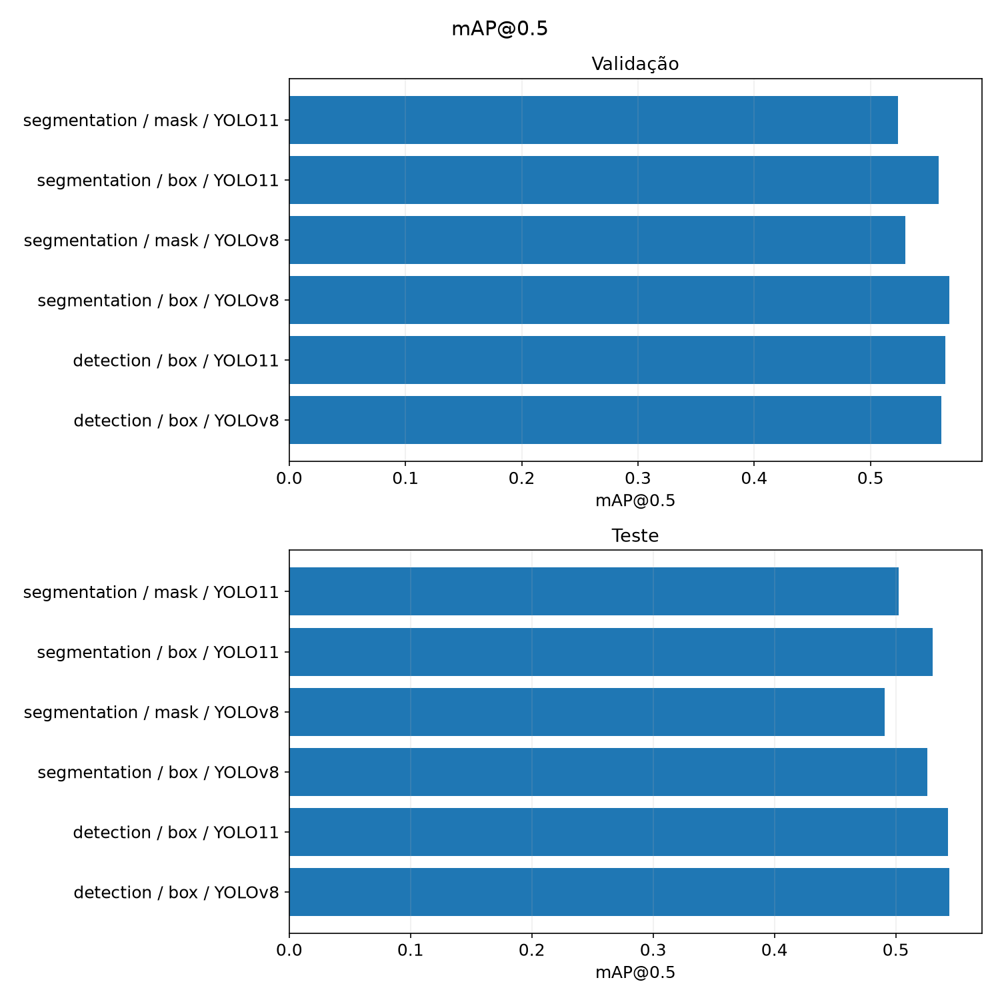

In [27]:
display(Image(filename=str(ROOT / 'graficos/comparativo_map50.png')))

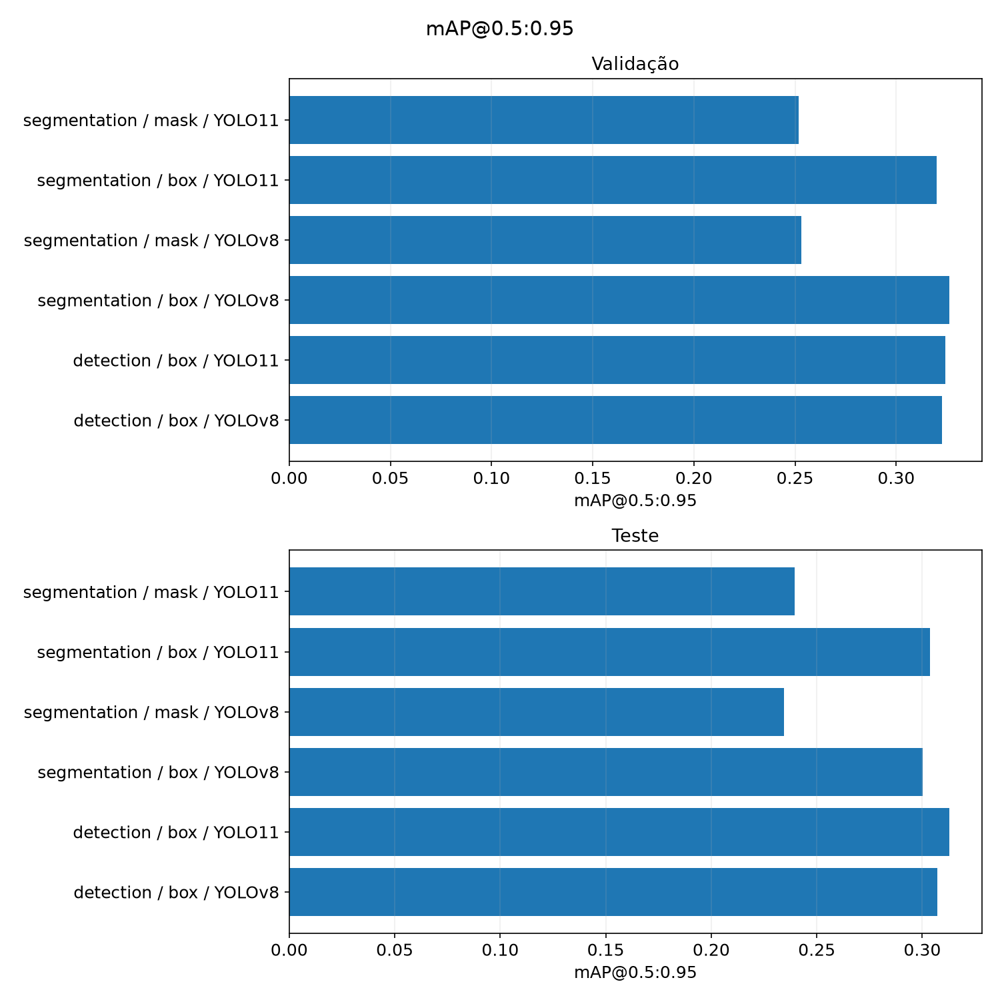

In [28]:
display(Image(filename=str(ROOT / 'graficos/comparativo_map50_95.png')))

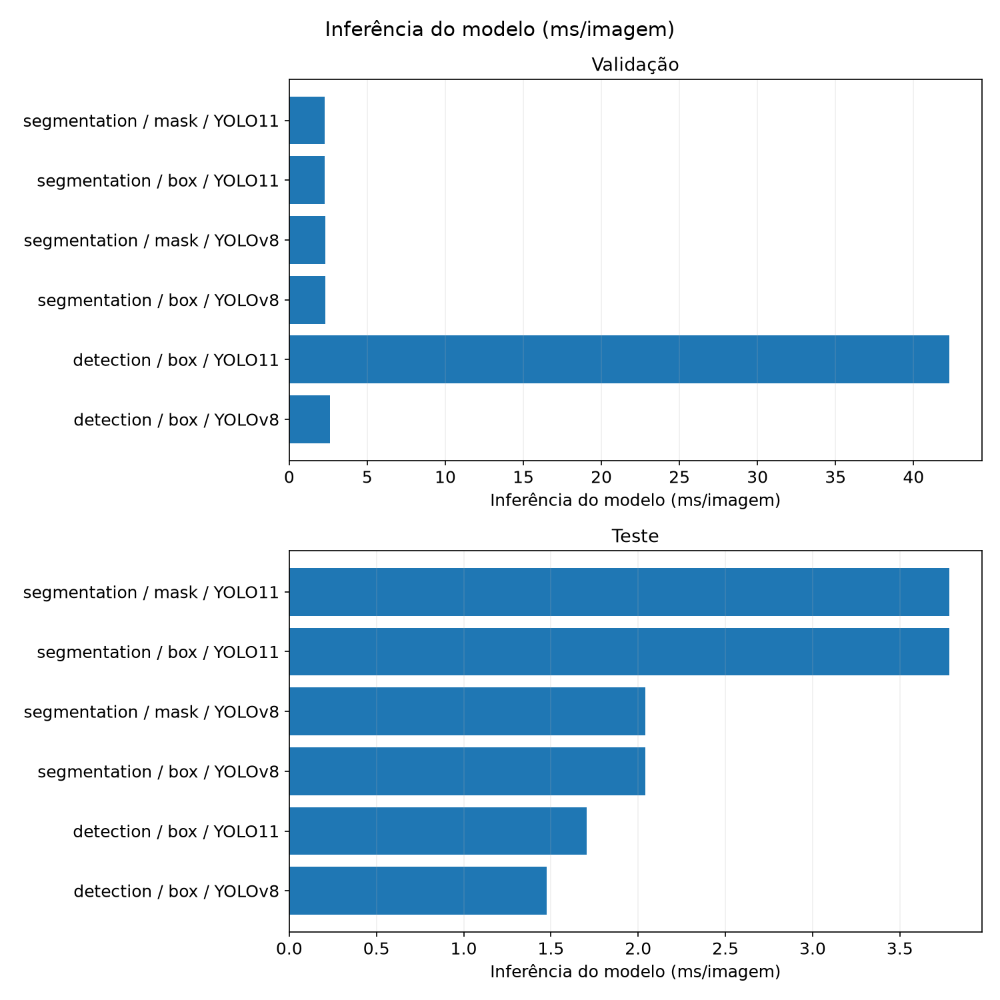

In [29]:
display(Image(filename=str(ROOT / 'graficos/comparativo_inference_ms.png')))

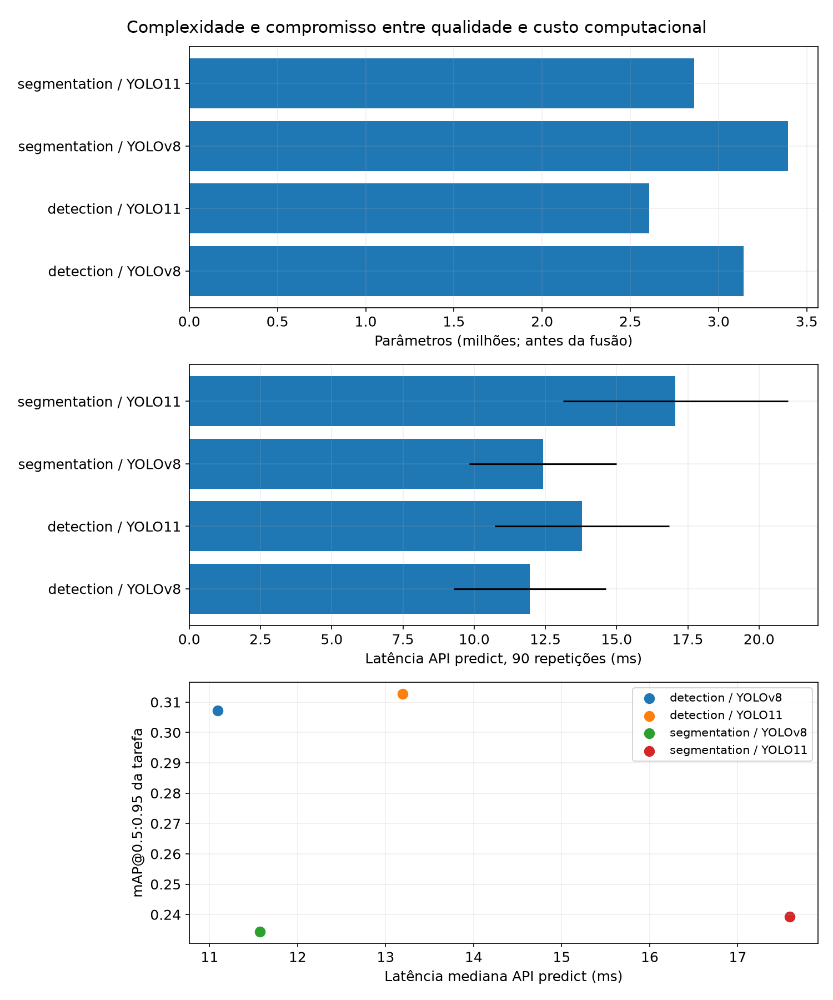

In [30]:
display(Image(filename=str(ROOT / 'graficos/eficiencia.png')))

## 14. Tabelas de resultados por classe
As tabelas agregadas da seção 12 são complementadas por AP e recall por classe, para revelar o efeito do desbalanceamento. Classes ausentes do conjunto avaliado não têm AP estimado.

In [31]:
for task,arch,_ in MODELS:
    for kind in (['box','mask'] if task=='segmentation' else ['box']):
        print(task,arch,kind,'teste')
        display(pd.read_csv(ROOT/'resultados'/task/arch/'avaliacao_test'/f'classes_{kind}.csv').round(4))

detection YOLOv8 box teste


,class_id,classe,precision,recall,map50,map50_95
0,0,Open blade disconnect switch,0.6253,0.3000,0.3272,0.1235
1,1,Closed blade disconnect switch,0.7860,0.6504,0.6936,0.4712
2,2,Open tandem disconnect switch,0.5942,0.2090,0.2585,0.1144
3,3,Closed tandem disconnect switch,0.6736,0.4307,0.4669,0.2160
4,4,Breaker,0.8092,0.6821,0.7215,0.4674
5,5,Fuse disconnect switch,0.8475,0.6889,0.7718,0.4792
6,6,Glass disc insulator,0.7020,0.4730,0.5004,0.2532
7,7,Porcelain pin insulator,0.7550,0.5682,0.6265,0.3408
8,8,Muffle,0.5665,0.4674,0.4519,0.1919
9,9,Lightning arrester,0.6248,0.3924,0.4586,0.1911


detection YOLO11 box teste


,class_id,classe,precision,recall,map50,map50_95
0,0,Open blade disconnect switch,0.6531,0.1500,0.2433,0.1047
1,1,Closed blade disconnect switch,0.7886,0.6495,0.6945,0.4777
2,2,Open tandem disconnect switch,0.4934,0.1791,0.2368,0.1124
3,3,Closed tandem disconnect switch,0.6413,0.4959,0.5455,0.2397
4,4,Breaker,0.8421,0.6712,0.7431,0.4608
5,5,Fuse disconnect switch,0.9700,0.6667,0.7565,0.5185
6,6,Glass disc insulator,0.6543,0.4949,0.5127,0.2682
7,7,Porcelain pin insulator,0.7648,0.5613,0.6205,0.3374
8,8,Muffle,0.6375,0.4559,0.4827,0.2187
9,9,Lightning arrester,0.6554,0.4272,0.4530,0.1875


segmentation YOLOv8 box teste


...

,class_id,classe,precision,recall,map50,map50_95
0,0,Open blade disconnect switch,0.4127,0.0532,0.0853,0.0205
1,1,Closed blade disconnect switch,0.7333,0.6281,0.6387,0.3514
2,2,Open tandem disconnect switch,0.5888,0.2388,0.2519,0.0960
3,3,Closed tandem disconnect switch,0.5510,0.4453,0.4584,0.1564
4,4,Breaker,0.7609,0.6230,0.6523,0.4105
5,5,Fuse disconnect switch,0.6386,0.4667,0.5411,0.2557
6,6,Glass disc insulator,0.6795,0.4645,0.4947,0.1487
7,7,Porcelain pin insulator,0.6890,0.5541,0.5928,0.2531
8,8,Muffle,0.5463,0.4215,0.3983,0.1313
9,9,Lightning arrester,0.6045,0.3291,0.3669,0.1206


segmentation YOLO11 box teste


,class_id,classe,precision,recall,map50,map50_95
0,0,Open blade disconnect switch,0.7255,0.1000,0.1979,0.0712
1,1,Closed blade disconnect switch,0.7793,0.6337,0.6781,0.4659
2,2,Open tandem disconnect switch,0.6373,0.2338,0.2672,0.1184
3,3,Closed tandem disconnect switch,0.7540,0.4818,0.5126,0.2497
4,4,Breaker,0.8148,0.7078,0.7408,0.4609
5,5,Fuse disconnect switch,0.7544,0.5778,0.6941,0.4501
6,6,Glass disc insulator,0.6677,0.4706,0.4931,0.2527
7,7,Porcelain pin insulator,0.7044,0.6041,0.6252,0.3429
8,8,Muffle,0.5363,0.5249,0.4915,0.2222
9,9,Lightning arrester,0.6803,0.4114,0.4517,0.1860


segmentation YOLO11 mask teste


,class_id,classe,precision,recall,map50,map50_95
0,0,Open blade disconnect switch,0.5624,0.0750,0.1410,0.0380
1,1,Closed blade disconnect switch,0.7722,0.6072,0.6450,0.3515
2,2,Open tandem disconnect switch,0.6103,0.2182,0.2561,0.0878
3,3,Closed tandem disconnect switch,0.7587,0.4745,0.5015,0.1410
4,4,Breaker,0.8223,0.6795,0.7261,0.4383
5,5,Fuse disconnect switch,0.6741,0.5058,0.5706,0.2740
6,6,Glass disc insulator,0.6877,0.4706,0.4824,0.1626
7,7,Porcelain pin insulator,0.6815,0.5568,0.5933,0.2534
8,8,Muffle,0.5209,0.4707,0.4325,0.1507
9,9,Lightning arrester,0.6200,0.3562,0.3515,0.1142


## 15. Predições reais
As três primeiras imagens por nome no teste são mostradas sem seleção por qualidade; conf visual = 0,25. A segmentação mostra máscaras previstas, distintas das máscaras de verdade usadas na validação visual.

### detection — YOLOv8

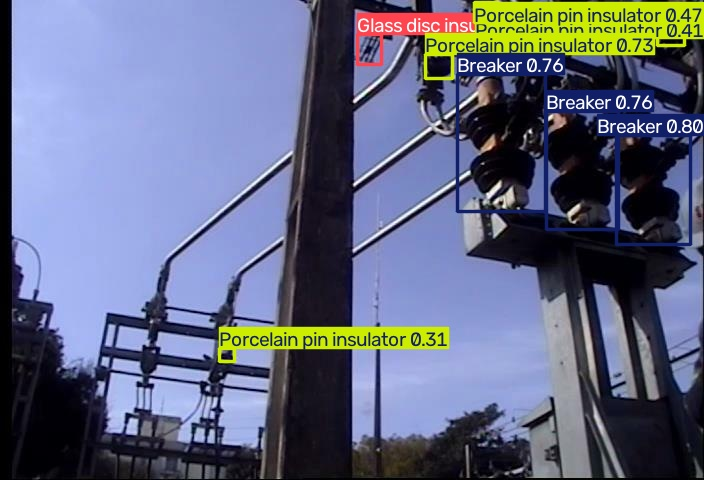

In [32]:
display(Image(filename=str(ROOT/'resultados/detection/YOLOv8/avaliacao_test/predicao_1.jpg'), width=1000))

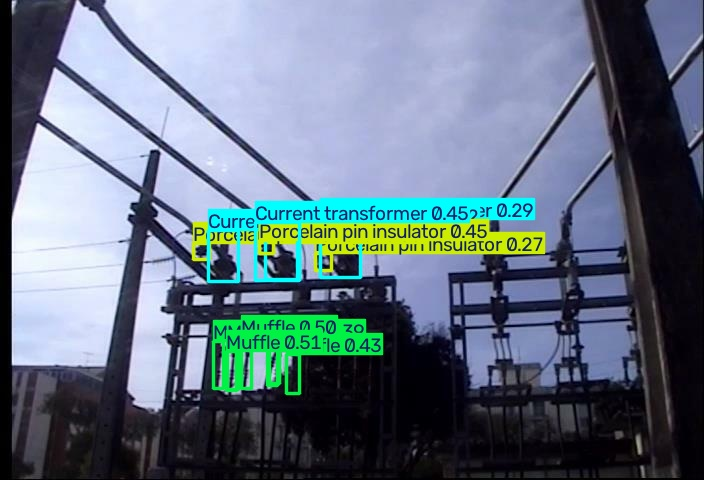

In [33]:
display(Image(filename=str(ROOT/'resultados/detection/YOLOv8/avaliacao_test/predicao_2.jpg'), width=1000))

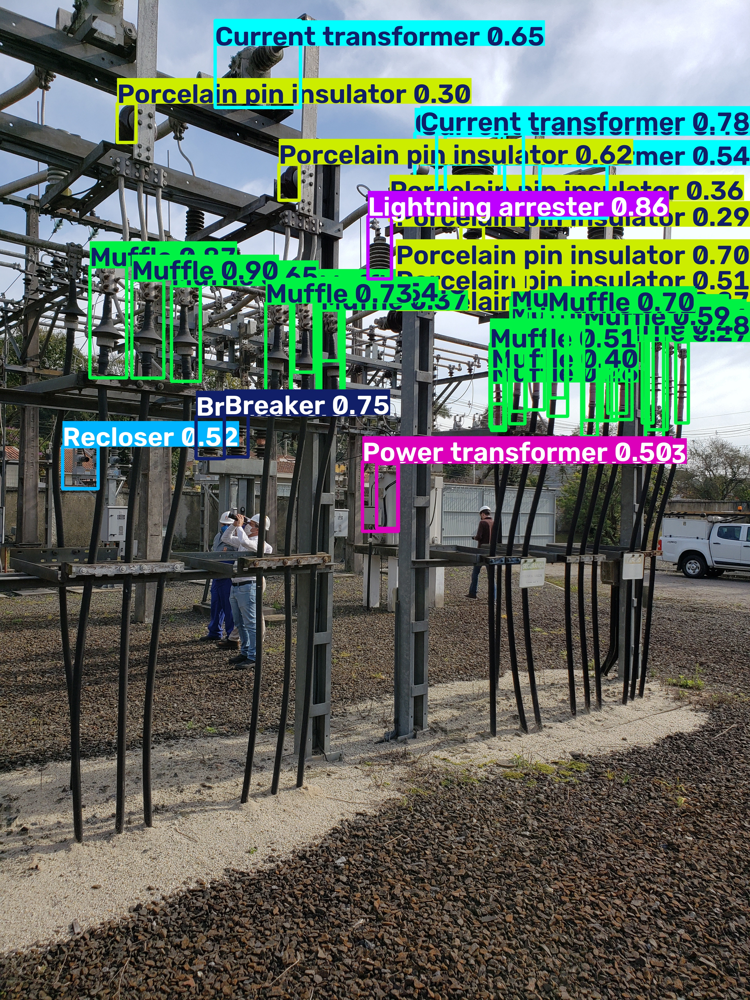

In [34]:
display(Image(filename=str(ROOT/'resultados/detection/YOLOv8/avaliacao_test/predicao_3.jpg'), width=1000))

### detection — YOLO11

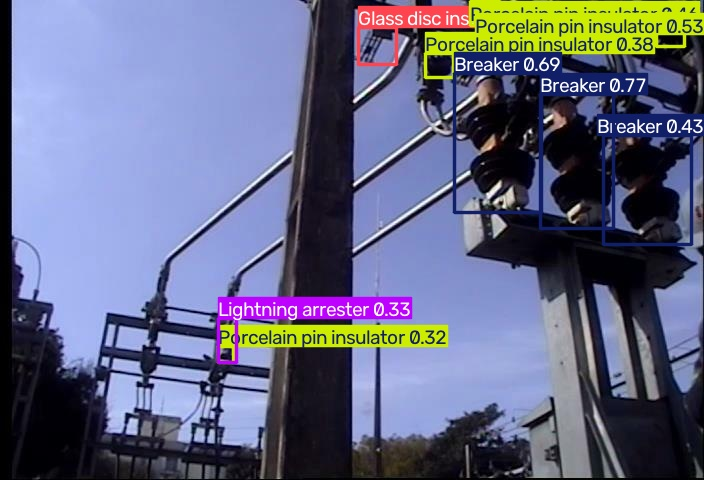

In [35]:
display(Image(filename=str(ROOT/'resultados/detection/YOLO11/avaliacao_test/predicao_1.jpg'), width=1000))

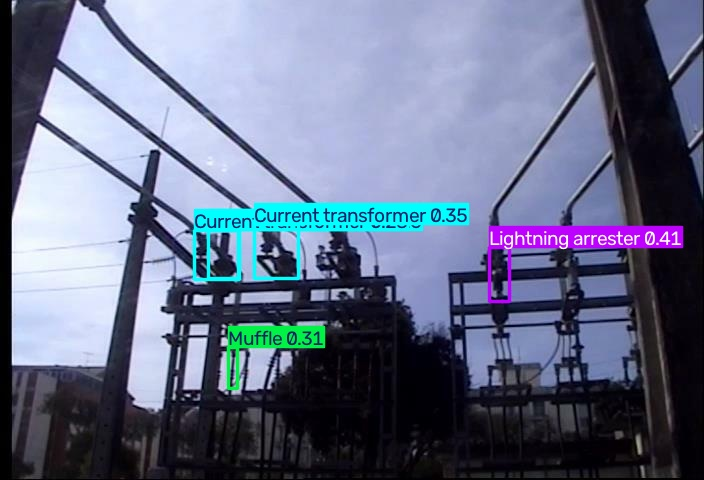

In [36]:
display(Image(filename=str(ROOT/'resultados/detection/YOLO11/avaliacao_test/predicao_2.jpg'), width=1000))

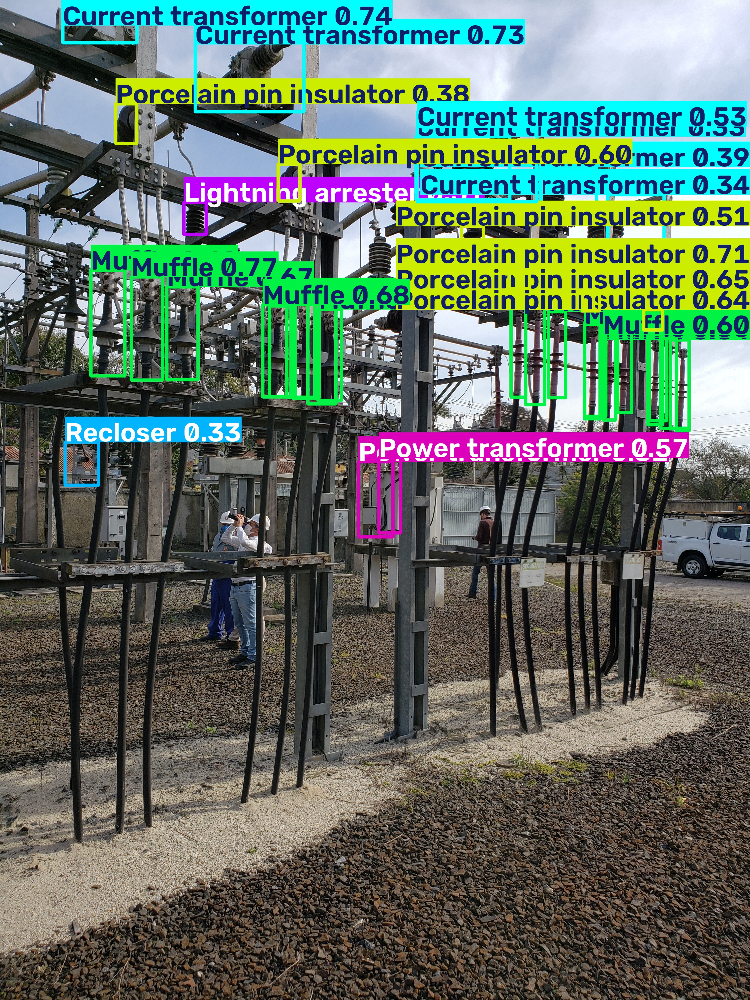

In [37]:
display(Image(filename=str(ROOT/'resultados/detection/YOLO11/avaliacao_test/predicao_3.jpg'), width=1000))

### segmentation — YOLOv8

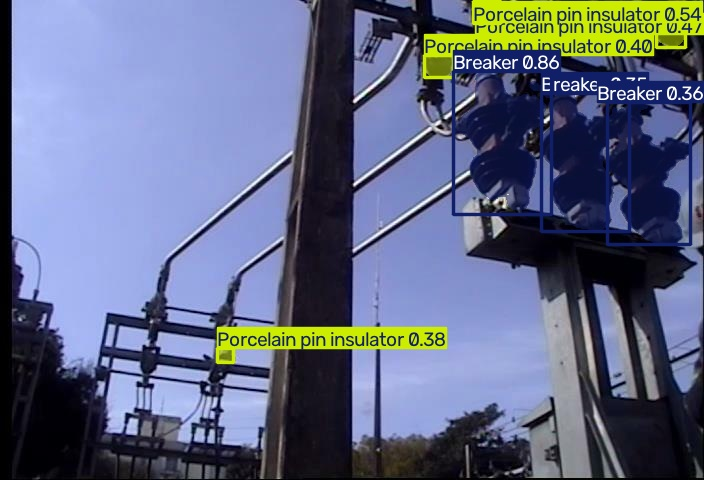

In [38]:
display(Image(filename=str(ROOT/'resultados/segmentation/YOLOv8/avaliacao_test/predicao_1.jpg'), width=1000))

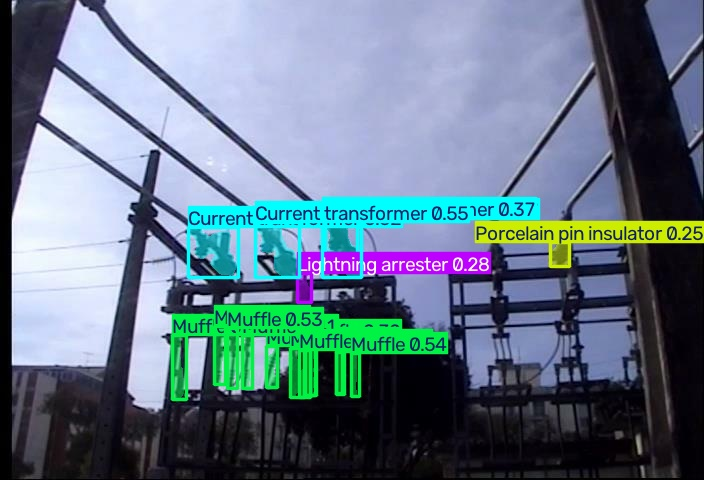

In [39]:
display(Image(filename=str(ROOT/'resultados/segmentation/YOLOv8/avaliacao_test/predicao_2.jpg'), width=1000))

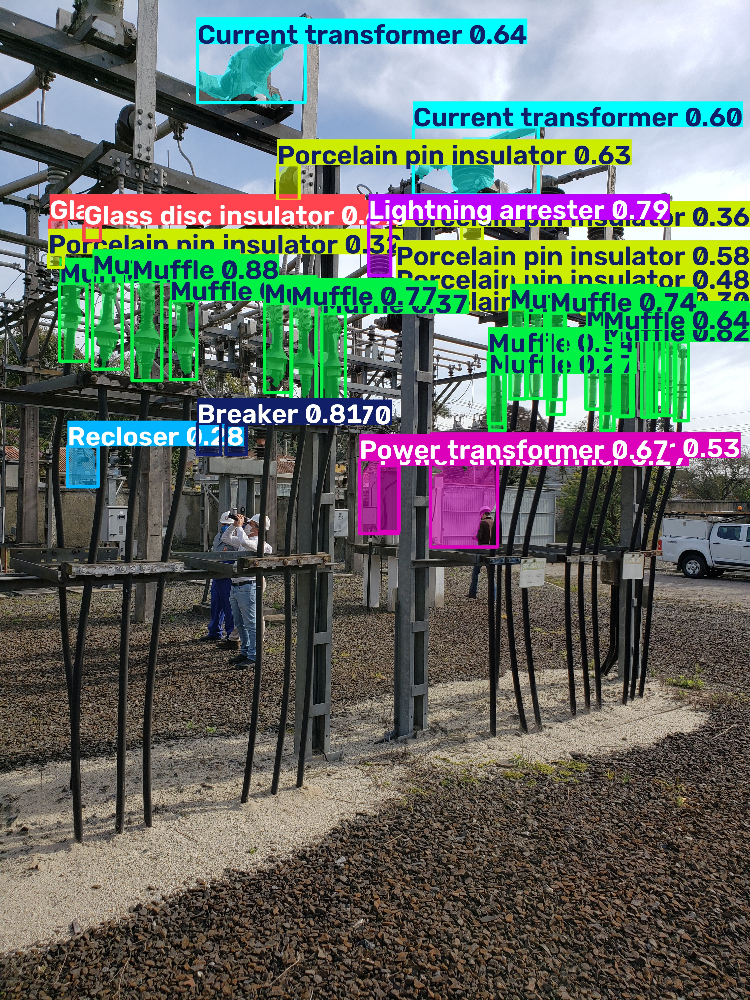

In [40]:
display(Image(filename=str(ROOT/'resultados/segmentation/YOLOv8/avaliacao_test/predicao_3.jpg'), width=1000))

### segmentation — YOLO11

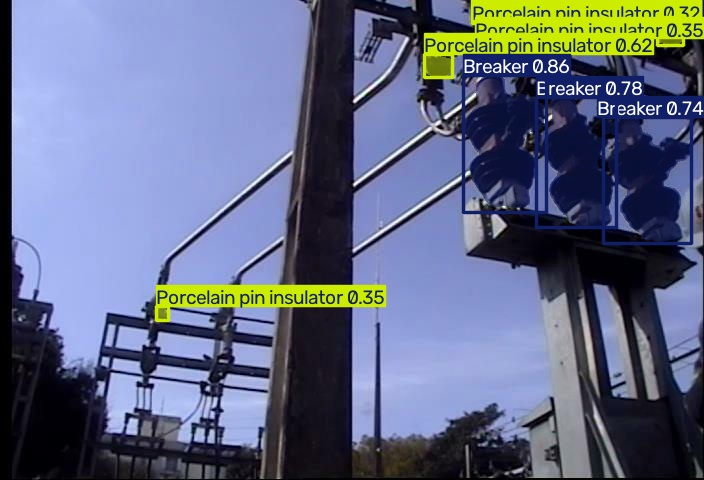

In [41]:
display(Image(filename=str(ROOT/'resultados/segmentation/YOLO11/avaliacao_test/predicao_1.jpg'), width=1000))

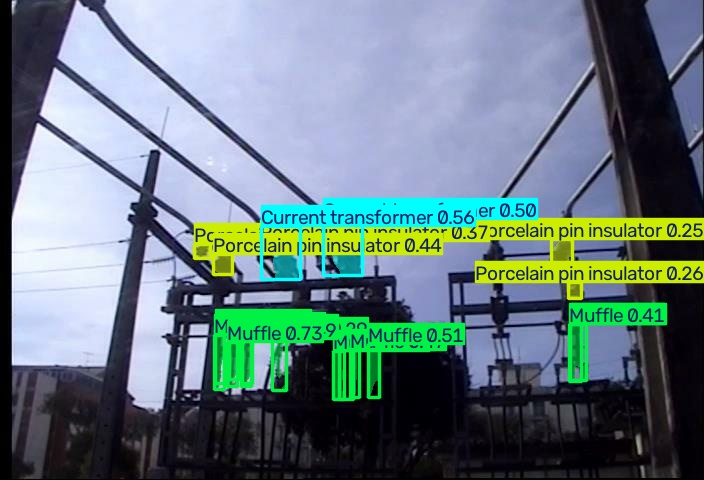

In [42]:
display(Image(filename=str(ROOT/'resultados/segmentation/YOLO11/avaliacao_test/predicao_2.jpg'), width=1000))

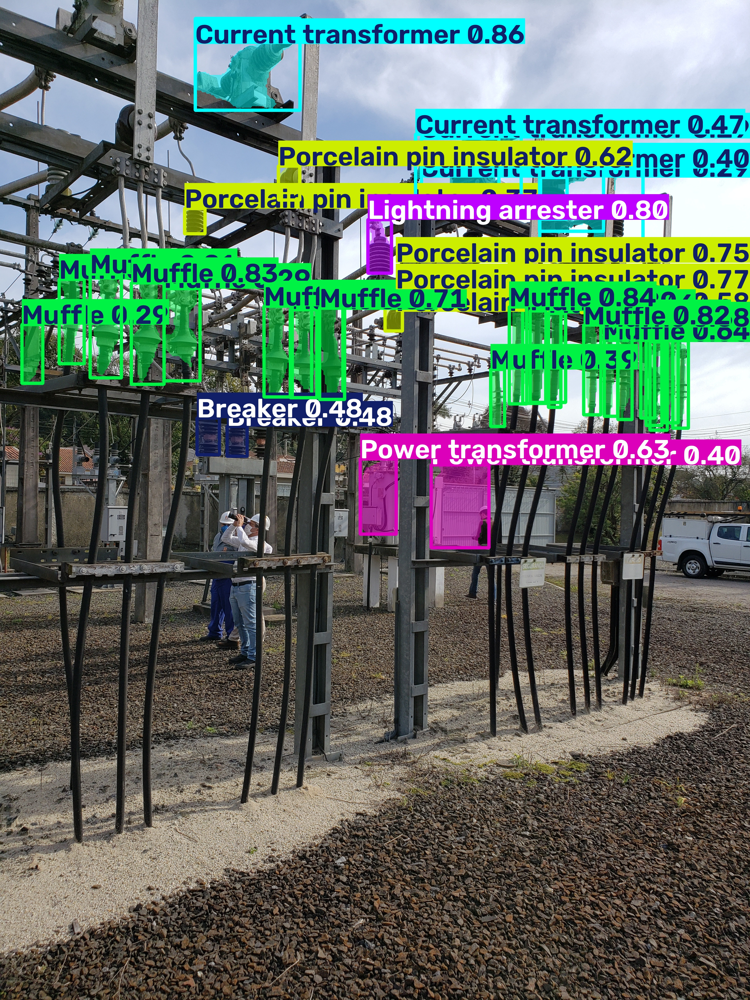

In [43]:
display(Image(filename=str(ROOT/'resultados/segmentation/YOLO11/avaliacao_test/predicao_3.jpg'), width=1000))

## 16. Análise crítica

Na detecção, o mAP@0.5:0.95 no teste foi 0.3072 para YOLOv8 e 0.3127 para YOLO11. A diferença YOLO11 − YOLOv8 foi +0.0054; a maior pontuação observada foi YOLO11. Isso descreve esta execução e esta divisão, sem demonstrar superioridade estatística ou generalização para outras subestações. Precision/recall foram 0.7231/0.5020 e 0.7352/0.4869, respectivamente.

No benchmark complementar da API predict em lote 1, a latência média foi 11.95 ± 2.67 ms no YOLOv8 e 13.78 ± 3.06 ms no YOLO11. As medianas foram 11.09 e 13.19 ms; os percentis 95 foram 17.00 e 18.66 ms. Foram dez aquecimentos e três rodadas de 30 repetições, sem remover valores atípicos. O ensaio inclui leitura, pré-processamento e pós-processamento da mesma imagem real de validação; difere do tempo interno do modelo medido sobre todo o teste. A quantidade de parâmetros foi 3,141,405 e 2,608,285. Variações térmicas, carga do Windows e tamanho dos objetos afetam o desempenho observado; diferenças de mediana não demonstram separação estatística.

Na segmentação de instâncias, o mAP@0.5:0.95 no teste foi 0.2344 para YOLOv8 e 0.2394 para YOLO11. A diferença YOLO11 − YOLOv8 foi +0.0050; a maior pontuação observada foi YOLO11. Isso descreve esta execução e esta divisão, sem demonstrar superioridade estatística ou generalização para outras subestações. Precision/recall foram 0.6662/0.4576 e 0.7013/0.4704, respectivamente.

No benchmark complementar da API predict em lote 1, a latência média foi 12.41 ± 2.58 ms no YOLOv8 e 17.07 ± 3.95 ms no YOLO11. As medianas foram 11.57 e 17.59 ms; os percentis 95 foram 18.08 e 23.11 ms. Foram dez aquecimentos e três rodadas de 30 repetições, sem remover valores atípicos. O ensaio inclui leitura, pré-processamento e pós-processamento da mesma imagem real de validação; difere do tempo interno do modelo medido sobre todo o teste. A quantidade de parâmetros foi 3,394,173 e 2,861,053. Variações térmicas, carga do Windows e tamanho dos objetos afetam o desempenho observado; diferenças de mediana não demonstram separação estatística.

detection, YOLOv8. Perdas de treinamento: train/box_loss: 2.5032 → 1.4075; train/cls_loss: 3.3402 → 0.9336; train/dfl_loss: 1.5208 → 1.0077. Perdas de validação: val/box_loss: 2.0575 → 1.4639, variação das médias das últimas duas janelas de 3 épocas = -0.0404; val/cls_loss: 2.1913 → 0.9489, variação das médias das últimas duas janelas de 3 épocas = -0.0492; val/dfl_loss: 1.3745 → 1.0606, variação das médias das últimas duas janelas de 3 épocas = -0.0122. Vinte épocas constituem um orçamento fixo; redução de perda não prova convergência. A estabilidade das últimas janelas e as curvas de AP devem ser interpretadas juntas, especialmente após o encerramento do mosaico. Não foram realizados novos ajustes após consultar o teste.

detection, YOLOv8: a variação da média de AP entre as duas últimas janelas de três épocas foi +0.0198. As janelas finais ainda variam; as 20 épocas não demonstram estabilização suficiente por esse critério descritivo. O critério descritivo adotado foi variação inferior a 2% em todos os componentes não nulos da perda de validação e inferior a 0,01 no AP; não é um teste estatístico nem foi usado para mudar o treinamento.

detection, YOLO11. Perdas de treinamento: train/box_loss: 2.4909 → 1.4138; train/cls_loss: 3.3951 → 0.9311; train/dfl_loss: 1.4933 → 1.0061. Perdas de validação: val/box_loss: 2.0384 → 1.4499, variação das médias das últimas duas janelas de 3 épocas = -0.0478; val/cls_loss: 2.6513 → 0.9574, variação das médias das últimas duas janelas de 3 épocas = -0.0478; val/dfl_loss: 1.2831 → 1.0398, variação das médias das últimas duas janelas de 3 épocas = -0.0161. Vinte épocas constituem um orçamento fixo; redução de perda não prova convergência. A estabilidade das últimas janelas e as curvas de AP devem ser interpretadas juntas, especialmente após o encerramento do mosaico. Não foram realizados novos ajustes após consultar o teste.

detection, YOLO11: a variação da média de AP entre as duas últimas janelas de três épocas foi +0.0208. As janelas finais ainda variam; as 20 épocas não demonstram estabilização suficiente por esse critério descritivo. O critério descritivo adotado foi variação inferior a 2% em todos os componentes não nulos da perda de validação e inferior a 0,01 no AP; não é um teste estatístico nem foi usado para mudar o treinamento.

segmentation, YOLOv8. Perdas de treinamento: train/box_loss: 2.4735 → 1.4024; train/seg_loss: 3.7456 → 2.3313; train/cls_loss: 3.3333 → 0.9555; train/dfl_loss: 1.4567 → 0.9952; train/sem_loss: 0.0000 → 0.0000. Perdas de validação: val/box_loss: 2.0205 → 1.4438, variação das médias das últimas duas janelas de 3 épocas = -0.0295; val/seg_loss: 3.2857 → 2.3407, variação das médias das últimas duas janelas de 3 épocas = -0.0532; val/cls_loss: 2.2762 → 0.9652, variação das médias das últimas duas janelas de 3 épocas = -0.0365; val/dfl_loss: 1.3099 → 1.0343, variação das médias das últimas duas janelas de 3 épocas = -0.0099; val/sem_loss: 0.0000 → 0.0000, variação das médias das últimas duas janelas de 3 épocas = +0.0000. Vinte épocas constituem um orçamento fixo; redução de perda não prova convergência. A estabilidade das últimas janelas e as curvas de AP devem ser interpretadas juntas, especialmente após o encerramento do mosaico. Não foram realizados novos ajustes após consultar o teste.

segmentation, YOLOv8: a variação da média de AP entre as duas últimas janelas de três épocas foi +0.0132. As janelas finais ainda variam; as 20 épocas não demonstram estabilização suficiente por esse critério descritivo. O critério descritivo adotado foi variação inferior a 2% em todos os componentes não nulos da perda de validação e inferior a 0,01 no AP; não é um teste estatístico nem foi usado para mudar o treinamento.

segmentation, YOLO11. Perdas de treinamento: train/box_loss: 2.4595 → 1.4074; train/seg_loss: 3.7045 → 2.3095; train/cls_loss: 3.3340 → 0.9651; train/dfl_loss: 1.4741 → 0.9884; train/sem_loss: 0.0000 → 0.0000. Perdas de validação: val/box_loss: 2.0261 → 1.4447, variação das médias das últimas duas janelas de 3 épocas = -0.0450; val/seg_loss: 3.1925 → 2.3067, variação das médias das últimas duas janelas de 3 épocas = -0.0752; val/cls_loss: 2.4887 → 0.9847, variação das médias das últimas duas janelas de 3 épocas = -0.0419; val/dfl_loss: 1.3246 → 1.0344, variação das médias das últimas duas janelas de 3 épocas = -0.0159; val/sem_loss: 0.0000 → 0.0000, variação das médias das últimas duas janelas de 3 épocas = +0.0000. Vinte épocas constituem um orçamento fixo; redução de perda não prova convergência. A estabilidade das últimas janelas e as curvas de AP devem ser interpretadas juntas, especialmente após o encerramento do mosaico. Não foram realizados novos ajustes após consultar o teste.

segmentation, YOLO11: a variação da média de AP entre as duas últimas janelas de três épocas foi +0.0137. As janelas finais ainda variam; as 20 épocas não demonstram estabilização suficiente por esse critério descritivo. O critério descritivo adotado foi variação inferior a 2% em todos os componentes não nulos da perda de validação e inferior a 0,01 no AP; não é um teste estatístico nem foi usado para mudar o treinamento.

O desbalanceamento observado varia de 308 objetos em Open blade disconnect switch a 26448 em Porcelain pin insulator, razão de 85.9:1. O mAP macro atribui o mesmo peso às classes presentes; os CSVs por classe permitem identificar se classes raras tiveram baixo recall. Nenhuma classe foi removida por conveniência.

Como indicador geométrico, 69.9% das caixas têm área inferior a 32² pixels após normalização para uma imagem 640×640. Isso é uma aproximação; o letterbox preserva a proporção e pode reduzir ainda mais a área útil. Objetos pequenos e oclusões dificultam localizar bordas e distinguir porcelanas próximas. Não foi calculado AP COCO por escala; esse indicador não demonstra sozinho uma queda de AP para objetos pequenos.

As anotações foram publicadas para segmentação semântica. Aqui cada polígono sem group_id é uma instância operacional; polígonos com o mesmo group_id e classe permanecem agrupados. Fragmentos de um objeto físico sem identificador podem permanecer separados. Os registros de correções informam reparos, recortes, pontes entre partes e eventual preenchimento de furos, limitações que afetam a fidelidade das máscaras. As caixas são envoltórias dos mesmos objetos usados na segmentação.

A divisão usa seed 42 e é idêntica nas duas tarefas, com agrupamento de duplicatas exatas por SHA256. Imagens próximas no tempo ou ponto de vista podem permanecer em conjuntos diferentes. O dataset contém uma única subestação, portanto a estimativa não representa validação externa. Houve apenas uma semente, sem intervalos de confiança e sem busca de hiperparâmetros; ganhos pequenos devem ser interpretados com cautela.

As medições originais de latência mostraram dispersão, incluindo tempo interno de 42,27 ms na validação do detector YOLO11 e uma janela E2E do detector YOLOv8 com desvio próximo da própria média. Inicialização, aquecimento, compilação ou carga do sistema podem contribuir, mas a causa exata não foi isolada. Essas observações foram preservadas integralmente. Por isso, a análise de latência estável usa também o benchmark complementar em validação, com mediana e P95; nenhum peso, hiperparâmetro ou resultado de qualidade foi alterado após o teste.

## 17. Conclusão

Para o cenário medido, as escolhas condicionais são: para detecção, maior qualidade medida: YOLO11; menor latência de API: YOLOv8; para segmentação de instâncias, maior qualidade medida: YOLO11; menor latência de API: YOLOv8. Se a prioridade for qualidade global, recomenda-se o maior mAP de teste da tarefa; se a prioridade for resposta rápida, a menor latência observada, verificando o recall das classes de interesse. A maior pontuação nesta execução é evidência limitada ao protocolo, insuficiente para demonstrar superioridade estatística ou uma arquitetura universalmente melhor. Inspeções críticas requerem validação por equipamento e em outras subestações antes de uso operacional.

Os quatro experimentos foram limitados a 20 épocas por exigência do protocolo. Nenhum resultado funcional foi incluído nas tabelas finais.

## 18. Referências
- Gomes, A. et al. A Semantically Annotated 15-Class Ground Truth Dataset for Substation Equipment. Zenodo, 2023. https://doi.org/10.5281/zenodo.7884270
- Ultralytics. YOLOv8. https://docs.ultralytics.com/models/yolov8/
- Ultralytics. YOLO11. https://docs.ultralytics.com/models/yolo11/
- Ultralytics. Train, Val e Segment: https://docs.ultralytics.com/modes/train/ ; https://docs.ultralytics.com/modes/val/ ; https://docs.ultralytics.com/tasks/segment/
- PyTorch. Reproducibility. https://pytorch.org/docs/stable/notes/randomness.html

Versões executadas estão no diagnóstico e no requirements.txt. Reprodutibilidade numérica exata entre hardware/versões não é garantida.

## Apêndice — reprodução e código-fonte
Execute no PowerShell, na raiz do projeto:
```powershell
.\.venv\Scripts\python.exe -u src/pipeline.py
```
Para reconstruir apenas a análise e o PDF, sem treinar:
```powershell
.\.venv\Scripts\python.exe src/pipeline.py --report-only
```
O código a seguir é a implementação preservada no projeto, exibida para revisão.

### common.py
```python
"""Configuração compartilhada; caminhos independentes do diretório do terminal."""
from pathlib import Path
import json
import os
import time

ROOT = Path(__file__).resolve().parents[1]
os.environ.setdefault('MPLCONFIGDIR', str(ROOT/'config/matplotlib'))
for key,folder in [('IPYTHONDIR','ipython'),('JUPYTER_CONFIG_DIR','jupyter'),('JUPYTER_DATA_DIR','jupyter_data'),('JUPYTER_RUNTIME_DIR','jupyter_runtime')]:
    os.environ.setdefault(key,str(ROOT/'config'/folder))
    Path(os.environ[key]).mkdir(parents=True,exist_ok=True)
MODELS = [('detection', 'YOLOv8', 'yolov8n.pt'),
          ('detection', 'YOLO11', 'yolo11n.pt'),
          ('segmentation', 'YOLOv8', 'yolov8n-seg.pt'),
          ('segmentation', 'YOLO11', 'yolo11n-seg.pt')]
TRAIN = dict(epochs=20, imgsz=640, batch=8, optimizer='SGD', lr0=0.01,
             seed=42, device=0, amp=True, patience=0, workers=0,
             deterministic=True, cache=False, save=True, plots=True,
             overlap_mask=False, mask_ratio=4)

def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix('.tmp')
    with temp.open('w',encoding='utf-8') as stream:
        json.dump(value,stream,indent=2,ensure_ascii=False,default=str)
    temp.replace(path)

def load_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def log(message):
    print(time.strftime('%Y-%m-%d %H:%M:%S'), message, flush=True)

```

### download.py
```python
"""Download retomável por intervalos, checksum oficial e extração segura."""
from concurrent.futures import ThreadPoolExecutor
import hashlib
import time
import zipfile
import requests
from common import ROOT, load_json, log

def download():
    base = ROOT/'dataset/original'
    base.mkdir(parents=True, exist_ok=True)
    meta = base/'zenodo_record.json'
    if not meta.exists():
        r = requests.get('https://zenodo.org/api/records/7884270', timeout=120)
        r.raise_for_status()
        meta.write_text(r.text, encoding='utf-8')
    f = next(f for f in load_json(meta)['files'] if f['key']=='substation-semantic-dataset.zip')
    target = base/f['key']
    if not target.exists():
        part = target.with_suffix('.part')
        offset = part.stat().st_size if part.exists() else 0
        chunks = base/'download_parts'
        chunks.mkdir(exist_ok=True)
        size = 16*1024*1024
        spans = [(a,min(a+size,f['size'])-1) for a in range(offset,f['size'],size)]
        def fetch(span):
            a,b = span
            path = chunks/f'{a}-{b}'
            if path.exists() and path.stat().st_size == b-a+1:
                return path
            for attempt in range(6):
                try:
                    with requests.get(f['links']['self']+f'?range={a}', headers={'Range':f'bytes={a}-{b}'}, stream=True, timeout=120) as r:
                        r.raise_for_status()
                        if r.status_code != 206 or not r.headers.get('Content-Range','').startswith(f'bytes {a}-{b}/'):
                            raise ValueError('Resposta Range incompatível')
                        with path.with_suffix('.tmp').open('wb') as out:
                            for block in r.iter_content(1024*1024):
                                out.write(block)
                    if path.with_suffix('.tmp').stat().st_size != b-a+1:
                        raise ValueError('Intervalo incompleto')
                    path.with_suffix('.tmp').replace(path)
                    log(f'Download {a/1e6:.0f}–{b/1e6:.0f} MB concluído')
                    return path
                except Exception:
                    if attempt == 5:
                        raise
                    time.sleep(2**attempt)
        with ThreadPoolExecutor(max_workers=6) as pool:
            paths = list(pool.map(fetch,spans))
        with part.open('ab') as out:
            for p in paths:
                with p.open('rb') as inp:
                    while block := inp.read(8*1024*1024):
                        out.write(block)
        part.rename(target)
    expected = f['checksum'].split(':')[1]
    with target.open('rb') as stream:
        actual = hashlib.file_digest(stream,'md5').hexdigest()
    if actual != expected:
        raise ValueError(f'Checksum incorreto: {actual} != {expected}; arquivo preservado')
    log('MD5 original validado: '+actual)
    extracted = base/'extracted'
    if not (extracted/'.complete').exists():
        extracted.mkdir(exist_ok=True)
        with zipfile.ZipFile(target) as z:
            for info in z.infolist():
                dest = (extracted/info.filename).resolve()
                if not dest.is_relative_to(extracted.resolve()):
                    raise ValueError('Caminho inseguro no ZIP')
                z.extract(info,extracted)
        (extracted/'.complete').write_text(actual)
    return extracted

if __name__=='__main__':
    download()

```

### prepare.py
```python
"""Inspeção e conversão LabelMe → YOLO, sem alterar os dados originais."""
from collections import Counter, defaultdict
import hashlib
import random
import shutil
import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from shapely import make_valid
from shapely.geometry import Polygon, box
import yaml
from common import ROOT, load_json, save_json, log
from download import download

def polygon_parts(geom):
    if geom.is_empty:
        return []
    if geom.geom_type=='Polygon':
        return [geom] if geom.area>0 else []
    return [p for g in getattr(geom,'geoms',[]) for p in polygon_parts(g)]

def prepare():
    marker=ROOT/'relatorios/preparacao.json'
    if marker.exists():
        log('Conversão já concluída; preservada')
        return load_json(marker)
    base=download()
    classes=[s.strip() for s in (base/'classes.txt').read_text(encoding='utf-8-sig').splitlines() if s.strip() and s.strip().lower()!='background']
    ids={c:i for i,c in enumerate(classes)}
    assert len(classes)==15
    images={}
    for p in (base/'images').iterdir():
        if p.suffix.lower() in {'.jpg','.jpeg','.png'}:
            if p.stem in images:
                raise ValueError('Nome de imagem duplicado: '+p.stem)
            images[p.stem]=p
    annotations={p.stem:p for p in (base/'labels_json').glob('*.json')}
    masks={}
    for directory in sorted(base.glob('*masks')):
        files={p.stem:p for p in directory.glob('*.png')}
        samples=[]
        for stem in sorted(files)[:3]:
            with Image.open(files[stem]) as mask:
                samples.append(dict(file=files[stem].name,mode=mask.mode,size=list(mask.size),colors=mask.getcolors(maxcolors=32)))
        masks[directory.name]=dict(files=len(files),missing_for_images=sorted(images.keys()-files.keys()),orphan_masks=sorted(files.keys()-images.keys()),samples=samples,
                                   usage='Inspeção semântica; não usado como identidade de instâncias')
    save_json(ROOT/'relatorios/inspecao_mascaras.json',masks)
    issues=[]
    records=[]
    types=Counter()
    grouped=0
    for stem,p in sorted(images.items()):
        if stem not in annotations:
            issues.append(dict(image=stem,action='imagem excluída',reason='JSON ausente')); continue
        try:
            with Image.open(p) as im:
                im.load()
                w,h=im.size
                orientation=im.getexif().get(274,1)
                if orientation in {5,6,7,8}:
                    w,h=h,w
                if orientation!=1:
                    issues.append(dict(image=stem,action='interpretação EXIF',reason=f'Orientação {orientation}: dimensões orientadas, como JSON e OpenCV/Ultralytics; bytes originais preservados'))
            j=load_json(annotations[stem])
            if (j['imageWidth'],j['imageHeight'])!=(w,h):
                raise ValueError('Dimensão JSON difere da imagem')
        except Exception as exc:
            issues.append(dict(image=stem,action='imagem excluída',reason=str(exc))); continue
        groups=defaultdict(list)
        for k,s in enumerate(j['shapes']):
            types[s.get('shape_type','polygon')]+=1
            key=(s['label'].strip(), 'shape', k) if s.get('group_id') is None else (s['label'].strip(),'group',s['group_id'])
            groups[key].append((k,s))
        objects=[]
        seen_polygons=set()
        for key,shapes in groups.items():
            label=key[0]
            parts=[]
            if label.lower()=='background':
                issues.append(dict(image=stem,group=str(key),action='fundo ignorado',reason='Background não é uma classe de equipamento YOLO'))
                continue
            try:
                if label not in ids:
                    raise ValueError('Classe desconhecida: '+label)
                for k,s in shapes:
                    if s.get('shape_type','polygon')!='polygon':
                        raise ValueError('Tipo não poligonal: '+str(s.get('shape_type')))
                    a=np.asarray(s['points'],dtype=float)
                    if a.ndim!=2 or a.shape[1]!=2 or not np.isfinite(a).all() or len(np.unique(a,axis=0))<3:
                        raise ValueError('Vértices insuficientes ou não finitos')
                    geom=Polygon(a)
                    if not geom.is_valid:
                        geom=make_valid(geom)
                        issues.append(dict(image=stem,shape=k,action='corrigida',reason='make_valid: polígono inválido'))
                    if (a[:,0]<0).any() or (a[:,0]>w).any() or (a[:,1]<0).any() or (a[:,1]>h).any():
                        geom=geom.intersection(box(0,0,w,h))
                        issues.append(dict(image=stem,shape=k,action='corrigida',reason='recorte geométrico nos limites da imagem'))
                    parts.extend(polygon_parts(geom))
                if not parts:
                    raise ValueError('Área nula após validação')
                # Partes de um group_id permanecem UMA instância; pontes de largura zero
                # são necessárias porque o TXT YOLO não armazena MultiPolygon ou furos.
                from shapely.ops import unary_union
                union=unary_union(parts)
                parts=polygon_parts(union)
                if any(len(p.interiors) for p in parts):
                    issues.append(dict(image=stem,group=str(key),action='limitação',reason='formato YOLO não representa furos; usa contorno externo'))
                contours=[np.asarray(p.exterior.coords)[:-1] for p in parts]
                if len(contours)>1:
                    from ultralytics.data.converter import merge_multi_segment
                    a=np.concatenate(merge_multi_segment(contours),axis=0)
                    issues.append(dict(image=stem,group=str(key),action='corrigida',reason='partes da mesma instância unidas com pontes de largura zero'))
                else:
                    a=contours[0]
                normalized=np.clip(a/np.array([w,h]),0,1)
                x1,y1,x2,y2=union.bounds
                bbox=np.array([(x1+x2)/2/w,(y1+y2)/2/h,(x2-x1)/w,(y2-y1)/h])
                assert np.isfinite(normalized).all() and (bbox[2:]>0).all()
                # Duplicatas literalmente idênticas não representam outra instância.
                signature=(ids[label],normalized.tobytes())
                if signature in seen_polygons:
                    issues.append(dict(image=stem,group=str(key),action='duplicata excluída',reason='Mesma classe e mesmos vértices normalizados de outro objeto'))
                    continue
                seen_polygons.add(signature)
                objects.append(dict(class_id=ids[label],bbox=bbox.tolist(),polygon=normalized.tolist(),area_fraction=union.area/(w*h)))
                grouped+=len(shapes)>1
            except Exception as exc:
                issues.append(dict(image=stem,group=str(key),action='objeto excluído',reason=str(exc)))
        with p.open('rb') as stream:
            digest=hashlib.file_digest(stream,'sha256').hexdigest()
        records.append(dict(stem=stem,image=str(p.relative_to(ROOT)),json=str(annotations[stem].relative_to(ROOT)),width=w,height=h,sha256=digest,objects=objects))
        if len(records)%100==0:
            log(f'Inspecionadas {len(records)}/{len(images)} imagens')
    for stem in annotations.keys()-images.keys():
        issues.append(dict(image=stem,action='JSON órfão',reason='imagem ausente'))
    present={o['class_id'] for r in records for o in r['objects']}
    if present!=set(range(len(classes))):
        raise RuntimeError('Uma ou mais classes não têm nenhum objeto válido: revise a conversão antes de treinar')
    # Imagens byte a byte idênticas são agrupadas para evitar vazamento exato.
    unique=defaultdict(list)
    for r in records:
        unique[r['sha256']].append(r)
    groups=list(unique.values())
    random.Random(42).shuffle(groups)
    n=len(records); targets=[round(n*.7),round(n*.15)]
    split_names=['train','val','test']; split=0; used=0
    for group in groups:
        if split<2 and used>=targets[split]:
            split+=1; used=0
        for r in group:
            r['split']=split_names[split]
        used+=len(group)
    assert not (set(r['sha256'] for r in records if r['split']=='train') & set(r['sha256'] for r in records if r['split']!='train'))
    rows=[]
    for r in records:
        stem=r['stem']; subset=r['split']
        for task in ['detection','segmentation']:
            dest=ROOT/'dataset'/task
            image_dest=dest/'images'/subset/(stem+Path(r['image']).suffix.lower())
            image_dest.parent.mkdir(parents=True,exist_ok=True)
            if not image_dest.exists():
                # Cópias independentes: nenhum reparo JPEG posterior pode tocar o original.
                shutil.copy2(ROOT/r['image'],image_dest)
            label_dest=dest/'labels'/subset/(stem+'.txt')
            label_dest.parent.mkdir(parents=True,exist_ok=True)
            lines=[]
            for o in r['objects']:
                coords=o['bbox'] if task=='detection' else np.asarray(o['polygon']).flatten()
                lines.append(str(o['class_id'])+' '+' '.join(f'{v:.9f}' for v in coords))
            label_dest.write_text('\n'.join(lines)+'\n' if lines else '',encoding='utf-8')
        counts=Counter(o['class_id'] for o in r['objects'])
        for cid,name in enumerate(classes):
            rows.append(dict(image=stem,split=subset,class_id=cid,classe=name,objetos=counts[cid]))
    for task in ['detection','segmentation']:
        cfg=dict(path=(ROOT/'dataset'/task).as_posix(),train='images/train',val='images/val',test='images/test',names=dict(enumerate(classes)))
        (ROOT/'config'/f'{task}.yaml').write_text(yaml.safe_dump(cfg,allow_unicode=True),encoding='utf-8')
    df=pd.DataFrame(rows)
    df.to_csv(ROOT/'relatorios/distribuicao_imagens_classes.csv',index=False)
    df.groupby(['split','class_id','classe']).objetos.sum().to_csv(ROOT/'relatorios/distribuicao_classes.csv')
    save_json(ROOT/'relatorios/anotacoes_convertidas.json',records)
    save_json(ROOT/'relatorios/correcoes_descartes.json',issues)
    inventory={p.name:len(list(p.iterdir())) for p in base.iterdir() if p.is_dir()}
    report=dict(classes=classes,images_original=len(images),json_original=len(annotations),valid_images=n,
                objects=sum(len(r['objects']) for r in records),splits=dict(Counter(r['split'] for r in records)),
                annotation_types=dict(types),grouped_instances=grouped,exact_duplicate_images=n-len(unique),
                issues=len(issues),inventory=inventory,seed=42,split_method='shuffle de grupos SHA256; 70/15/15 com arredondamento',
                limitation='Uma única subestação; divisão aleatória não garante independência de pontos de vista ou datas. Polígonos sem group_id são tratados como instâncias anotadas, não identidade física rastreada.')
    visualize(records,classes)
    save_json(marker,report)
    log(str(report))
    return report

def visualize(records,classes):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    from matplotlib.patches import Polygon as PatchPolygon, Rectangle
    from matplotlib.lines import Line2D
    colors=plt.get_cmap('tab20')
    for idx,r in enumerate(random.Random(42).sample(records,3)):
        image=ImageOps.exif_transpose(Image.open(ROOT/r['image'])); image.thumbnail((1200,1200))
        w,h=image.size
        fig,axes=plt.subplots(1,3,figsize=(19,7))
        for ax,title in zip(axes,['Original','Caixas derivadas dos polígonos','Instâncias anotadas']):
            ax.imshow(image); ax.set_title(title); ax.axis('off')
        for o in r['objects']:
            c=colors(o['class_id']); x,y,bw,bh=o['bbox']
            axes[1].add_patch(Rectangle(((x-bw/2)*w,(y-bh/2)*h),bw*w,bh*h,fill=False,edgecolor=c,lw=1))
            axes[2].add_patch(PatchPolygon(np.array(o['polygon'])*[w,h],facecolor=c,edgecolor=c,alpha=.35,lw=.7))
        present=sorted(set(o['class_id'] for o in r['objects']))
        fig.legend(handles=[Line2D([0],[0],color=colors(c),lw=4,label=classes[c]) for c in present],loc='lower center',ncol=4,fontsize=8)
        fig.suptitle(f"{r['stem']} | {len(r['objects'])} instâncias | conjunto: {r['split']}")
        fig.tight_layout(rect=[0,.15,1,.95]); fig.savefig(ROOT/'graficos'/f'validacao_{idx+1}.png',dpi=140); plt.close(fig)
        for kind,title in [('original','Original'),('boxes','Caixas derivadas'),('polygons','Polígonos anotados')]:
            fig,ax=plt.subplots(figsize=(11,9))
            ax.imshow(image); ax.axis('off'); ax.set_title(f"{r['stem']} — {title}",fontsize=15)
            if kind!='original':
                for o in r['objects']:
                    c=colors(o['class_id']); x,y,bw,bh=o['bbox']
                    if kind=='boxes':
                        ax.add_patch(Rectangle(((x-bw/2)*w,(y-bh/2)*h),bw*w,bh*h,fill=False,edgecolor=c,lw=1))
                    else:
                        ax.add_patch(PatchPolygon(np.array(o['polygon'])*[w,h],facecolor=c,edgecolor=c,alpha=.35,lw=.7))
                fig.legend(handles=[Line2D([0],[0],color=colors(c),lw=4,label=classes[c]) for c in present],loc='lower center',ncol=2,fontsize=13)
            fig.tight_layout(rect=[0,.20,1,.96]); fig.savefig(ROOT/'graficos'/f'validacao_{idx+1}_{kind}.png',dpi=140); plt.close(fig)
    df=pd.read_csv(ROOT/'relatorios/distribuicao_classes.csv')
    table=df.pivot(index='classe',columns='split',values='objetos').fillna(0)
    table.plot.barh(stacked=True,figsize=(12,8)); plt.xlabel('Objetos anotados'); plt.ylabel('Classe'); plt.title('Distribuição das instâncias por classe e divisão'); plt.tight_layout(); plt.savefig(ROOT/'graficos/distribuicao.png',dpi=150); plt.close()

from pathlib import Path
if __name__=='__main__':
    prepare()

```

### train.py
```python
"""Um modelo por processo CUDA; testes funcionais isolados dos resultados finais."""
import argparse
import gc
import time
import shutil
from common import ROOT, TRAIN, MODELS, load_json, save_json, log
import numpy as np
import pandas as pd
import torch
import psutil
import yaml
from ultralytics import YOLO

def smoke_yaml(task):
    records=load_json(ROOT/'relatorios/anotacoes_convertidas.json')
    candidates=[r for r in records if r['split']=='train']
    # Amostra inclui imagens densas, objetos pequenos e dimensões grandes.
    ordered=sorted(candidates,key=lambda r:len(r['objects']),reverse=True)
    selected=ordered[:8]+sorted(candidates,key=lambda r:r['width']*r['height'],reverse=True)[:8]
    selected=list({r['stem']:r for r in selected}.values())
    images=ROOT/'dataset'/task/'images/train'
    lookup={p.stem:p for p in images.iterdir()}
    listing=ROOT/'config'/f'smoke_{task}.txt'
    listing.write_text('\n'.join(lookup[r['stem']].as_posix() for r in selected),encoding='utf-8')
    cfg=yaml.safe_load((ROOT/'config'/f'{task}.yaml').read_text(encoding='utf-8'))
    cfg.update(train=listing.as_posix(),val=listing.as_posix())
    cfg.pop('test',None)
    path=ROOT/'config'/f'smoke_{task}.yaml'
    path.write_text(yaml.safe_dump(cfg,allow_unicode=True),encoding='utf-8')
    return path

def run(task,arch,batch=8,smoke=False):
    if not torch.cuda.is_available():
        raise RuntimeError('CUDA indisponível: treinamento completo em CPU bloqueado.')
    weight=next(m for t,a,m in MODELS if (t,a)==(task,arch))
    folder=ROOT/'resultados'/task/arch
    if smoke:
        folder=ROOT/'resultados/funcional'/task/f'{arch}_batch{batch}'
    complete=folder/'concluido.json'
    if complete.exists():
        log(f'Experimento concluído preservado: {folder}')
        return
    csv=folder/'results.csv'
    if csv.exists() and len(pd.read_csv(csv))==(1 if smoke else 20) and (folder/'weights/best.pt').exists():
        # Recupera a finalização interrompida após a última época.
        args=yaml.safe_load((folder/'args.yaml').read_text(encoding='utf-8'))
        if args['batch']!=batch or args['epochs']!=(1 if smoke else 20):
            raise RuntimeError('Resultados existentes com configuração diferente; preservados')
        save_json(complete,dict(recovered=True,batch=batch,epochs=len(pd.read_csv(csv))))
        return
    ckpt=folder/'weights/last.pt'
    if folder.exists() and any(folder.iterdir()) and not ckpt.exists():
        # Tentativa sem checkpoint é mantida para auditoria, nunca sobrescrita.
        backup=folder.with_name(folder.name+'_interrompido_'+time.strftime('%Y%m%d_%H%M%S'))
        folder.rename(backup)
    data=smoke_yaml(task) if smoke else ROOT/'config'/f'{task}.yaml'
    model=YOLO(str(ckpt) if ckpt.exists() else str(ROOT/weight))
    timings_path=folder/'tempos_epocas.json'
    timings=load_json(timings_path) if timings_path.exists() else []
    clock={}
    expected_epochs=1 if smoke else 20
    def epoch_start(trainer):
        clock['start']=time.perf_counter()
        torch.cuda.reset_peak_memory_stats()
        if trainer.batch_size!=batch:
            raise RuntimeError('BATCH_ALTERADO_POR_OOM: necessário ajustar ambos os modelos da tarefa')
    def epoch_end(trainer):
        # Ultralytics também chama este evento na validação final de best.pt,
        # com epoch=epochs; esse evento não constitui uma época adicional.
        if trainer.epoch>=expected_epochs:
            return
        if trainer.batch_size!=batch:
            raise RuntimeError('BATCH_ALTERADO_POR_OOM: necessário ajustar ambos os modelos da tarefa')
        elapsed=time.perf_counter()-clock['start']
        timings.append(dict(epoch=trainer.epoch+1,seconds=elapsed,
                            cuda_peak_allocated_bytes=torch.cuda.max_memory_allocated(),
                            cuda_free_bytes=torch.cuda.mem_get_info()[0],batch=trainer.batch_size,
                            ram_available_bytes=psutil.virtual_memory().available,
                            process_rss_bytes=psutil.Process().memory_info().rss))
        save_json(timings_path,timings)
        log(f'Época {trainer.epoch+1}/{expected_epochs}: {elapsed:.1f} s; estimativa restante deste modelo: {elapsed*(expected_epochs-trainer.epoch-1)/60:.1f} min')
        if not smoke and trainer.epoch==0:
            position=next(i for i,(t,a,_) in enumerate(MODELS) if (t,a)==(task,arch))
            remaining=(20-1)+20*(len(MODELS)-position-1)
            estimate=dict(reference_model=f'{task}/{arch}',first_epoch_seconds=elapsed,
                          remaining_epochs=remaining,estimated_remaining_seconds=elapsed*remaining,
                          caveat='Estimativa preliminar: supõe custo por época igual ao atual; segmentação, aquecimento e fim do mosaico alteram a duração. Exclui avaliações e exportação.')
            save_json(ROOT/'relatorios/estimativa_duracao.json',estimate)
            log(f'Estimativa preliminar dos treinos restantes: {elapsed*remaining/3600:.2f} h, supondo o custo desta primeira época; segmentação pode ter custo diferente.')
    model.add_callback('on_train_epoch_start',epoch_start)
    model.add_callback('on_fit_epoch_end',epoch_end)
    started=time.perf_counter()
    cfg=dict(TRAIN,batch=batch,data=str(data),project=str(folder.parent),name=folder.name,exist_ok=True)
    if smoke:
        cfg.update(epochs=1,close_mosaic=0)
    if ckpt.exists():
        cfg.update(resume=str(ckpt))
    save_json(ROOT/'relatorios'/f'config_{task}_{arch}{"_funcional" if smoke else ""}.json',cfg)
    model.train(**cfg)
    torch.cuda.synchronize()
    if len(pd.read_csv(folder/'results.csv'))!=expected_epochs:
        raise RuntimeError('Número de épocas diferente do exigido')
    save_json(complete,dict(epochs=expected_epochs,batch=batch,seconds_this_session=time.perf_counter()-started,
                            epoch_seconds_total=sum(t['seconds'] for t in timings),
                            first_epoch_seconds=timings[0]['seconds'],functional=smoke,
                            effective_amp=bool(model.trainer.amp),effective_batch=model.trainer.batch_size,
                            optimizer_class=type(model.trainer.optimizer).__name__,
                            note='Tempos por época incluem validação; tempo de sessão inclui inicialização e avaliação final.'))
    del model
    gc.collect(); torch.cuda.empty_cache()

if __name__=='__main__':
    p=argparse.ArgumentParser(); p.add_argument('--task',choices=['detection','segmentation'],required=True)
    p.add_argument('--arch',choices=['YOLOv8','YOLO11'],required=True); p.add_argument('--batch',type=int,choices=[4,8],default=8)
    p.add_argument('--smoke',action='store_true'); a=p.parse_args()
    run(a.task,a.arch,a.batch,a.smoke)

```

### evaluate.py
```python
"""Avaliação final dos melhores checkpoints, sem ajustar com o conjunto de teste."""
import gc
import time
import hashlib
from common import ROOT, MODELS, load_json, save_json, log
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

def evaluate():
    if not torch.cuda.is_available():
        raise RuntimeError('Avaliação CUDA exigida para comparação de velocidade')
    rows=[]
    for task,arch,_ in MODELS:
        folder=ROOT/'resultados'/task/arch
        completed=load_json(folder/'concluido.json')
        if completed['epochs']!=20:
            raise RuntimeError('Experimento final incompleto')
        ckpt=folder/'weights/best.pt'
        digest=hashlib.sha256(ckpt.read_bytes()).hexdigest()
        for split in ['val','test']:
            output=folder/f'avaliacao_{split}'
            marker=output/'metricas.json'
            if marker.exists():
                record=load_json(marker)
                if record['checkpoint_sha256']!=digest:
                    raise RuntimeError('Checkpoint alterado após avaliação; resultados preservados')
                rows.extend(record['rows']); continue
            model=YOLO(str(ckpt))
            # Contagem antes da fusão de convoluções e BatchNorm.
            parameters=sum(p.numel() for p in model.model.parameters())
            metrics=model.val(data=str(ROOT/'config'/f'{task}.yaml'),split=split,imgsz=640,
                              batch=completed['batch'],device=0,workers=0,half=True,plots=True,
                              project=str(folder),name=f'avaliacao_{split}',exist_ok=True,
                              conf=.001,iou=.7,max_det=300,overlap_mask=False,mask_ratio=4,verbose=False)
            output.mkdir(exist_ok=True)
            selected=[]
            for kind,metric in [('box',metrics.box)]+([('mask',metrics.seg)] if task=='segmentation' else []):
                row=dict(task=task,model=arch,split=split,metric_type=kind,precision=float(metric.mp),recall=float(metric.mr),
                         map50=float(metric.map50),map50_95=float(metric.map),parameters=parameters,
                         inference_ms=float(metrics.speed['inference']),preprocess_ms=float(metrics.speed['preprocess']),
                         postprocess_ms=float(metrics.speed['postprocess']),training_seconds=completed.get('epoch_seconds_total'),batch=completed['batch'])
                selected.append(row)
                perclass=[]
                for idx,cid in enumerate(metric.ap_class_index):
                    perclass.append(dict(class_id=int(cid),classe=model.names[int(cid)],precision=float(metric.p[idx]),
                                         recall=float(metric.r[idx]),map50=float(metric.ap50[idx]),map50_95=float(metric.ap[idx])))
                pd.DataFrame(perclass).to_csv(output/f'classes_{kind}.csv',index=False)
            # Benchmark separado: mesma imagem de validação, lote 1, aquecimento e 30 repetições.
            source=next((ROOT/'dataset'/task/'images/val').iterdir())
            for _ in range(5):
                model.predict(str(source),imgsz=640,device=0,half=True,verbose=False)
            elapsed=[]
            for _ in range(30):
                torch.cuda.synchronize(); start=time.perf_counter()
                model.predict(str(source),imgsz=640,device=0,half=True,verbose=False)
                torch.cuda.synchronize(); elapsed.append((time.perf_counter()-start)*1000)
            for row in selected:
                row.update(latency_e2e_mean_ms=float(np.mean(elapsed)),latency_e2e_std_ms=float(np.std(elapsed)))
            # Exemplos escolhidos por ordem de nome, nunca por qualidade da predição.
            samples=sorted((ROOT/'dataset'/task/'images'/split).iterdir())[:3]
            predictions=model.predict([str(p) for p in samples],imgsz=640,device=0,half=True,conf=.25,verbose=False)
            for i,pred in enumerate(predictions):
                pred.save(filename=str(output/f'predicao_{i+1}.jpg'))
            save_json(marker,dict(checkpoint_sha256=digest,rows=selected,speed=metrics.speed,
                                  benchmark=dict(image=str(source),warmup=5,repeats=30,batch=1,includes='leitura, pré-processamento, modelo e NMS; API predict'),
                                  metric_definition='AP IoU=0.50 e média IoU=0.50:0.95; precision/recall no ponto F1 ótimo da curva.'))
            rows.extend(selected)
            del model,metrics,predictions
            gc.collect(); torch.cuda.empty_cache()
    df=pd.DataFrame(rows)
    df.to_csv(ROOT/'relatorios/metricas_comparativas.csv',index=False)
    return df

if __name__=='__main__':
    evaluate()

```

### benchmark.py
```python
"""Latência adicional em validação; preserva as avaliações originais."""
import gc
import time
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO
from common import ROOT,MODELS,load_json,save_json

def benchmark():
    path=ROOT/'relatorios/benchmark_padronizado.json'
    if path.exists():
        return
    if not torch.cuda.is_available():
        raise RuntimeError('CUDA necessária para benchmark comparável')
    # Mesma imagem real em todas as arquiteturas; nenhum uso do teste para ajuste.
    source=sorted((ROOT/'dataset/detection/images/val').glob('*.jpg'))[0]
    results=[]
    observations=[]
    for task,arch,_ in MODELS:
        ckpt=ROOT/'resultados'/task/arch/'weights/best.pt'
        model=YOLO(str(ckpt))
        for _ in range(10):
            model.predict(str(source),imgsz=640,device=0,half=True,verbose=False)
        elapsed=[]
        for round_id in range(3):
            for sample in range(30):
                torch.cuda.synchronize(); start=time.perf_counter()
                model.predict(str(source),imgsz=640,device=0,half=True,verbose=False)
                torch.cuda.synchronize()
                ms=(time.perf_counter()-start)*1000
                elapsed.append(ms)
                observations.append(dict(task=task,model=arch,round=round_id+1,sample=sample+1,e2e_ms=ms))
        results.append(dict(task=task,model=arch,mean_ms=float(np.mean(elapsed)),std_ms=float(np.std(elapsed)),
                            median_ms=float(np.median(elapsed)),p95_ms=float(np.percentile(elapsed,95)),samples=len(elapsed)))
        del model
        gc.collect(); torch.cuda.empty_cache()
    pd.DataFrame(results).to_csv(ROOT/'relatorios/benchmark_padronizado.csv',index=False)
    pd.DataFrame(observations).to_csv(ROOT/'relatorios/benchmark_observacoes.csv',index=False)
    save_json(path,dict(image=str(source),warmup=10,rounds=3,repeats_per_round=30,batch=1,rows=results,
                        scope='API predict E2E: leitura + processamento + modelo + NMS, FP16 CUDA, imagem real de validação. Todos os valores mantidos, sem exclusão de outliers. Benchmark adicional motivado por dispersão nas medições originais, que foram preservadas.'))
    print(results,flush=True)

if __name__=='__main__':
    benchmark()

```

### pipeline.py
```python
"""Orquestrador sequencial, retomável e com bloqueio de execução concorrente."""
import argparse
import os
import subprocess
import sys
import time
import msvcrt
from common import ROOT, MODELS, save_json, load_json, log

def call(script,*args):
    log('Executando: '+script+' '+' '.join(args))
    cmd=[sys.executable,'-u',str(ROOT/'src'/script),*args]
    result=subprocess.run(cmd,cwd=ROOT)
    if result.returncode:
        raise RuntimeError(f'Processo falhou ({result.returncode}): {script}; consulte relatorios/pipeline.log')

def main():
    p=argparse.ArgumentParser(); p.add_argument('--report-only',action='store_true'); a=p.parse_args()
    lockpath=ROOT/'relatorios/pipeline.lock'
    lockpath.parent.mkdir(exist_ok=True)
    with lockpath.open('a+b') as lock:
        lock.seek(0); lock.write(b'1'); lock.flush(); lock.seek(0)
        try:
            msvcrt.locking(lock.fileno(),msvcrt.LK_NBLCK,1)
        except OSError:
            raise RuntimeError('Outro pipeline está ativo; execução concorrente bloqueada')
        statepath=ROOT/'relatorios/execucao.json'
        origin=ROOT/'dataset/original/zenodo_record.json'
        initial=origin.stat().st_birthtime if origin.exists() else time.time()
        state=load_json(statepath) if statepath.exists() else dict(started=initial,sessions=[],time_scope='Tempo corrido desde registro inicial do download; inclui download, preparação e execução.')
        started=time.time()
        state['status']='em execução'
        state.pop('error',None)
        save_json(statepath,state)
        try:
            if not a.report_only:
                call('environment.py')
                call('prepare.py')
                call('audit_source.py')
                call('validate_data.py')
                batches=load_json(ROOT/'config/batches.json') if (ROOT/'config/batches.json').exists() else {'detection':8,'segmentation':8}
                # Todos os testes funcionais precedem qualquer experimento final.
                for task in ['detection','segmentation']:
                    while True:
                        try:
                            for t,arch,_ in MODELS:
                                if t==task:
                                    call('train.py','--task',t,'--arch',arch,'--batch',str(batches[task]),'--smoke')
                            break
                        except RuntimeError:
                            # Um erro não identificado não autoriza alterar a metodologia.
                            # O operador verifica o log: somente CUDA OOM permite batch 4.
                            raise RuntimeError('Teste funcional falhou. Verifique o erro antes do treino final. Se CUDA OOM, use src/set_batch.py para batch 4 em AMBAS as arquiteturas da tarefa.')
                save_json(ROOT/'config/batches.json',batches)
                for task,arch,_ in MODELS:
                    call('train.py','--task',task,'--arch',arch,'--batch',str(batches[task]))
                call('evaluate.py')
                call('benchmark.py')
            call('report.py')
            state['status']='concluido'
            state.pop('error',None)
        except BaseException as exc:
            state['status']='interrompido'; state['error']=str(exc)
            raise
        finally:
            state['sessions'].append(dict(started=started,finished=time.time(),seconds=time.time()-started))
            state['active_seconds_total']=sum(s['seconds'] for s in state['sessions'])
            state['elapsed_wall_seconds']=time.time()-state['started']
            save_json(statepath,state)
            lock.seek(0); msvcrt.locking(lock.fileno(),msvcrt.LK_UNLCK,1)

if __name__=='__main__':
    main()

```